# Unidad 3 · Actividad 1 — Clasificación supervisada de texto
## Naive Bayes vs. Regresión Logística sobre *Amazon Fine Food Reviews*

**Objetivo.** Implementar un clasificador supervisado de texto (Naive Bayes y Regresión Logística) sobre el corpus preprocesado y vectorizado en las unidades anteriores, entrenarlo, generar predicciones y evaluar su desempeño con métricas adecuadas, analizando cómo la **representación textual** (BoW / TF-IDF, unigramas / bigramas, tratamiento de negaciones) condiciona el rendimiento del modelo.

**Tarea.** Clasificación binaria de sentimiento:
- **0 = Negativa**: reseñas de 1–2 estrellas.
- **1 = Positiva**: reseñas de 4–5 estrellas.
- Las reseñas de 3 estrellas se excluyen por ambiguas (en la Unidad 2 la clase neutral tuvo recall de 0,14).

### Cómo ejecutar
- **Único archivo necesario:** `corpus_amazon_procesado.csv.gz` (~92 MB), en la misma carpeta que el notebook. En Colab, la celda de carga pide subirlo si no lo encuentra (también lo busca en `/content/drive/MyDrive` si se monta Drive).
- **Librerías:** `pandas`, `numpy`, `scikit-learn`, `scipy`, `matplotlib`, `seaborn` y `nltk` (todas vienen instaladas en Colab).
- **Tiempo:** ~5 min en un portátil reciente, ~10–15 min en Colab (CPU). Memoria: ~2 GB (cabe de sobra en el Colab gratuito).
- **Salidas:** figuras en `figuras_actividad1/` y tablas `resultados_actividad1_test.csv` y `resultados_actividad1_validacion.csv`.

### Protocolo experimental

| Conjunto | Uso | Tamaño |
|---|---|---|
| **Entrenamiento** (80 %) | Se divide en *subentrenamiento* (85 %) y *validación* (15 %) para comparar representaciones, ajustar hiperparámetros y elegir el umbral. | 291.299 |
| **Prueba** (20 %) | Se usa **una sola vez**, al final, con los modelos ya elegidos. Es la misma partición estratificada (`random_state=42`) de las unidades anteriores. | 72.825 |

Todos los vectorizadores (vocabulario, IDF) se ajustan **solo** con los datos de entrenamiento de cada etapa, para evitar fuga de información.

### Relación con la rúbrica

| Criterio | Dónde se aborda |
|---|---|
| Implementación técnica del modelo | §2 partición, §4 modelos, §9 entrenamiento final, §10 validación cruzada |
| Uso adecuado de la representación textual | §3 representaciones, §5 matriz representación × modelo, §8 curva de aprendizaje, §11 interpretabilidad |
| Evaluación del desempeño | §5–§7 validación, §9 evaluación en prueba (accuracy, precision, recall, F1, MCC, ROC-AUC, PR-AUC…), intervalos bootstrap y McNemar |
| Análisis e interpretación | §12 análisis de errores, §13 robustez, §14 conclusiones, limitaciones y mejoras |

## 1. Configuración y carga de datos

In [1]:
import os, re, gc, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, cohen_kappa_score, roc_auc_score, average_precision_score,
    log_loss, brier_score_loss, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)
from scipy.stats import chi2

warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 42
np.random.seed(SEMILLA)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

NOMBRES_CLASES = ["Negativa", "Positiva"]
PALETA_SENT = {0: "#C0392B", 1: "#1E8449"}
COLORES_MODELO = {"NB": "#2E86C1", "LR": "#CA6F1E", "Base": "#7F8C8D"}

CARPETA_FIG = "figuras_actividad1"
os.makedirs(CARPETA_FIG, exist_ok=True)

def guardar_fig(nombre):
    plt.savefig(f"{CARPETA_FIG}/{nombre}.png", dpi=150, bbox_inches="tight")

print("Configuración lista.")

Configuración lista.


In [2]:
# ÚNICO archivo de datos necesario: corpus_amazon_procesado.csv.gz (~92 MB).
# Contiene las 393.892 reseñas sin duplicados de la Unidad 2 con tres columnas:
#   Text (original), Score (1-5) y Text_procesado (limpio, sin stopwords y lematizado con POS).
ARCHIVO_DATOS = "corpus_amazon_procesado.csv.gz"
UBICACIONES = [".", "/content", "/content/drive/MyDrive"]

def localizar_datos():
    for carpeta in UBICACIONES:
        for nombre in (ARCHIVO_DATOS, "df_corpus.csv"):   # df_corpus.csv: mismo contenido sin comprimir
            ruta = os.path.join(carpeta, nombre)
            if os.path.exists(ruta):
                return ruta
    return None

RUTA_CORPUS = localizar_datos()
if RUTA_CORPUS is None:
    try:
        from google.colab import files   # En Colab se pide subir el archivo
        print(f"Sube el archivo {ARCHIVO_DATOS}")
        files.upload()
        RUTA_CORPUS = localizar_datos()
    except ImportError:
        pass
if RUTA_CORPUS is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO_DATOS}. Colócalo en la misma carpeta que el notebook.")

t0 = time.time()
df_corpus = pd.read_csv(RUTA_CORPUS)
df_corpus["Text_procesado"] = df_corpus["Text_procesado"].fillna("")
print(f"Corpus cargado desde {RUTA_CORPUS} en {time.time() - t0:.1f} s: {df_corpus.shape}")

# Verificación de integridad: la partición de la Unidad 2 solo se reproduce con el corpus completo.
ESPERADO = {1: 36_302, 2: 20_801, 3: 29_768, 4: 56_087, 5: 250_934}
obtenido = df_corpus["Score"].value_counts().sort_index().to_dict()
if obtenido != ESPERADO:
    raise ValueError(
        f"El corpus cargado no coincide con el de la Unidad 2.\n"
        f"  Filas esperadas: {sum(ESPERADO.values()):,} | filas cargadas: {len(df_corpus):,}\n"
        f"  Reseñas por estrella esperadas: {ESPERADO}\n  Reseñas por estrella cargadas:  {obtenido}\n"
        "Causa habitual: la subida a Colab quedó incompleta o se cargó otro archivo. "
        f"Vuelve a subir {ARCHIVO_DATOS}.")
print("Integridad verificada: 393.892 reseñas con la distribución de puntuaciones esperada.")
display(df_corpus.head(3))

Corpus cargado desde ./corpus_amazon_procesado.csv.gz en 2.1 s: (393892, 3)
Integridad verificada: 393.892 reseñas con la distribución de puntuaciones esperada.


,Text,Score,Text_procesado
0,I have bought several of the Vitality canned d...,5,buy several vitality can dog food product find...
1,Product arrived labeled as Jumbo Salted Peanut...,1,product arrive labeled jumbo salt peanut ... p...
2,This is a confection that has been around a fe...,4,confection around century light pillowy citrus...


## 2. Corpus binario y partición entrenamiento / validación / prueba

Se reconstruye exactamente la partición de la Unidad 2 (estratificada, 80/20, `random_state=42`) y se verifica con los mismos tamaños. Después, el conjunto de entrenamiento se subdivide (85/15) para disponer de un conjunto de **validación** sobre el que se toman todas las decisiones de modelado.

In [3]:
df_bin = df_corpus[df_corpus["Score"] != 3].copy().reset_index(drop=True)
df_bin["Sentimiento"] = (df_bin["Score"] >= 4).astype(int)

idx = np.arange(len(df_bin))
idx_train, idx_test = train_test_split(
    idx, test_size=0.20, random_state=SEMILLA, stratify=df_bin["Sentimiento"])
idx_sub, idx_val = train_test_split(
    idx_train, test_size=0.15, random_state=SEMILLA,
    stratify=df_bin["Sentimiento"].values[idx_train])

y = df_bin["Sentimiento"].values
y_train, y_test = y[idx_train], y[idx_test]
y_sub, y_val = y[idx_sub], y[idx_val]

# Mismos tamaños que la partición binaria de la Unidad 2
print(f"Corpus binario: {len(df_bin):,} | entrenamiento: {len(idx_train):,} | prueba: {len(idx_test):,}")

resumen_part = pd.DataFrame({
    "Documentos": [len(idx_sub), len(idx_val), len(idx_train), len(idx_test)],
    "Negativas": [(y_sub == 0).sum(), (y_val == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "Positivas": [(y_sub == 1).sum(), (y_val == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
}, index=["Subentrenamiento", "Validación", "Entrenamiento (total)", "Prueba"])
resumen_part["% positivas"] = (resumen_part["Positivas"] / resumen_part["Documentos"] * 100).round(2)
display(resumen_part)

Corpus binario: 364,124 | entrenamiento: 291,299 | prueba: 72,825


,Documentos,Negativas,Positivas,% positivas
Subentrenamiento,247604,38830,208774,84.32
Validación,43695,6852,36843,84.32
Entrenamiento (total),291299,45682,245617,84.32
Prueba,72825,11421,61404,84.32


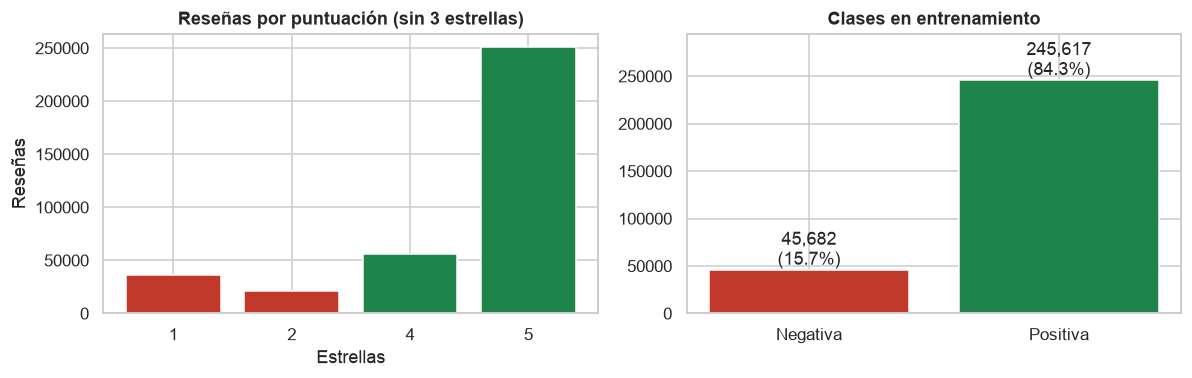

Línea base trivial (predecir siempre 'Positiva'): accuracy = 0.8432, F1 macro = 0.4575


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
conteo_score = df_bin["Score"].value_counts().sort_index()
axes[0].bar(conteo_score.index.astype(str), conteo_score.values,
            color=[PALETA_SENT[0]] * 2 + [PALETA_SENT[1]] * 2)
axes[0].set_title("Reseñas por puntuación (sin 3 estrellas)")
axes[0].set_xlabel("Estrellas"); axes[0].set_ylabel("Reseñas")

conteo = pd.Series(y_train).value_counts().sort_index()
axes[1].bar(NOMBRES_CLASES, conteo.values, color=[PALETA_SENT[0], PALETA_SENT[1]])
for i, v in enumerate(conteo.values):
    axes[1].text(i, v, f"{v:,}\n({v / conteo.sum():.1%})", ha="center", va="bottom")
axes[1].set_title("Clases en entrenamiento"); axes[1].set_ylim(0, conteo.max() * 1.2)
plt.tight_layout(); guardar_fig("01_distribucion_clases"); plt.show()

print(f"Línea base trivial (predecir siempre 'Positiva'): accuracy = {(y_test == 1).mean():.4f}, "
      f"F1 macro = {f1_score(y_test, np.ones_like(y_test), average='macro'):.4f}")

El corpus está muy desbalanceado (≈84 % positivas). Un clasificador trivial que siempre predice *Positiva* ya alcanza ≈84 % de accuracy, por lo que **el accuracy por sí solo no sirve para juzgar el modelo**: se priorizan F1 macro, recall de la clase negativa, accuracy balanceado, MCC y PR-AUC de la clase minoritaria.

## 3. Representaciones textuales

Se comparan seis representaciones, combinando tres decisiones:

| Fuente de texto | N-gramas | Ponderación |
|---|---|---|
| **Lematizado** (`Text_procesado`, Unidad 2) — sin stopwords | 1-gramas, 5.000 términos (igual que la Unidad 2) | BoW (conteos) / TF-IDF |
| **Lematizado** | 1–2-gramas, `min_df=5`, hasta 200.000 términos | BoW / TF-IDF sublineal |
| **Con negaciones** — texto original limpio (sin HTML, minúsculas, `n't → not`) **sin eliminar stopwords** | 1–2-gramas, `min_df=5`, hasta 200.000 términos | BoW / TF-IDF sublineal |

**¿Por qué una fuente "con negaciones"?** La lista de stopwords de NLTK usada en la Unidad 2 elimina palabras con carga de polaridad (*not, no, nor, but, very, too…*), y el tokenizador separaba *n't* como ruido. Así, "*not good*" y "*good*" quedaban representados igual. La celda siguiente lo verifica.

**Integración con cada modelo.**
- **BoW** (conteos enteros) corresponde exactamente al supuesto generativo de **Multinomial NB**: cada documento es una bolsa de palabras extraídas de una distribución multinomial por clase.
- **TF-IDF** reescala los conteos: reduce el peso de términos que aparecen en casi todas las reseñas (*product, taste*) y, con normalización L2, deja todos los documentos en la misma escala. Esto beneficia a la **Regresión Logística**, cuyo descenso por gradiente y regularización L2 funcionan mejor con variables de escala comparable. NB puede usar TF-IDF (pesos fraccionarios), pero se aleja de su supuesto de conteos.
- `sublinear_tf=True` usa `1 + log(tf)`, de modo que repetir una palabra 10 veces no pesa 10 veces más.

In [5]:
from nltk.corpus import stopwords
try:
    stop_en = set(stopwords.words("english"))
except LookupError:
    import nltk; nltk.download("stopwords", quiet=True)
    stop_en = set(stopwords.words("english"))

palabras_polaridad = ["not", "no", "nor", "but", "very", "too", "against", "don", "didn",
                      "wasn", "isn", "won", "few", "more", "most", "only"]
print("Palabras con carga de sentimiento eliminadas como stopwords en la Unidad 2:")
print([p for p in palabras_polaridad if p in stop_en])

# Ejemplo concreto: la negación desaparece del texto lematizado
fila = df_bin[df_bin["Text"].str.contains(r"\bnot good\b", case=False, regex=True)].iloc[0]
print("\nOriginal  :", fila["Text"][:220])
print("Lematizado:", fila["Text_procesado"][:220])

Palabras con carga de sentimiento eliminadas como stopwords en la Unidad 2:
['not', 'no', 'nor', 'but', 'very', 'too', 'against', 'don', 'didn', 'wasn', 'isn', 'won', 'few', 'more', 'most', 'only']



Original  : This oatmeal is not good. Its mushy, soft, I don't like it. Quaker Oats is the way to go.
Lematizado: oatmeal good mushy soft like quaker oat way go


In [6]:
def normalizar_con_negaciones(texto):
    # Limpieza ligera que conserva palabras funcionales y negaciones.
    texto = re.sub(r"<[^>]+>", " ", texto)          # etiquetas HTML (<br />)
    texto = re.sub(r"https?://\S+", " ", texto)      # URLs
    texto = texto.lower()
    texto = re.sub(r"won't", "will not", texto)
    texto = re.sub(r"can't", "can not", texto)
    texto = re.sub(r"n't\b", " not", texto)          # don't -> do not, isn't -> is not
    return texto

t0 = time.time()
df_bin["Text_negaciones"] = df_bin["Text"].fillna("").map(normalizar_con_negaciones)
print(f"Normalización completada en {time.time() - t0:.1f} s")
print("Con negaciones:", df_bin.loc[fila.name, "Text_negaciones"][:220])

FUENTES = {"lematizado": df_bin["Text_procesado"].values,
           "negaciones": df_bin["Text_negaciones"].values}

Normalización completada en 1.2 s
Con negaciones: this oatmeal is not good. its mushy, soft, i do not like it. quaker oats is the way to go.


In [7]:
# Configuraciones de vectorización. Para cada una se tokeniza una sola vez con
# CountVectorizer (BoW) y sobre esos conteos se ajusta un TfidfTransformer (TF-IDF).
CONFIG_VECT = {
    "1g-5k lematizado": dict(fuente="lematizado", sublineal=False,
                             params=dict(max_features=5000)),
    "1-2g lematizado":  dict(fuente="lematizado", sublineal=True,
                             params=dict(ngram_range=(1, 2), min_df=5, max_features=200_000)),
    "1-2g negaciones":  dict(fuente="negaciones", sublineal=True,
                             params=dict(ngram_range=(1, 2), min_df=5, max_features=200_000)),
}

def vectorizar(nombre_config, idx_ajuste, *idx_transformar):
    # Ajusta vocabulario e IDF solo con idx_ajuste y transforma el resto de índices.
    cfg = CONFIG_VECT[nombre_config]
    textos = FUENTES[cfg["fuente"]]
    cv = CountVectorizer(dtype=np.float32, **cfg["params"])
    bow = [cv.fit_transform(textos[idx_ajuste])] + [cv.transform(textos[i]) for i in idx_transformar]
    tfidf = TfidfTransformer(sublinear_tf=cfg["sublineal"])
    tf = [tfidf.fit_transform(bow[0])] + [tfidf.transform(m) for m in bow[1:]]
    return {"BoW": bow, "TF-IDF": tf, "vectorizador": cv}

REP = {}
info_rep = []
for nombre in CONFIG_VECT:
    t0 = time.time()
    REP[nombre] = vectorizar(nombre, idx_sub, idx_val)
    X = REP[nombre]["BoW"][0]
    info_rep.append({"Configuración": nombre,
                     "Vocabulario": X.shape[1],
                     "Términos no nulos / doc.": X.nnz / X.shape[0],
                     "Densidad (%)": X.nnz / (X.shape[0] * X.shape[1]) * 100,
                     "Tiempo (s)": time.time() - t0})
display(pd.DataFrame(info_rep).round(3))

,Configuración,Vocabulario,Términos no nulos / doc.,Densidad (%),Tiempo (s)
0,1g-5k lematizado,5000,30.174,0.603,4.045
1,1-2g lematizado,200000,54.459,0.027,17.118
2,1-2g negaciones,200000,108.198,0.054,23.881


Las matrices son **extremadamente dispersas** (menos del 1 % de celdas no nulas), por eso se almacenan en formato `scipy.sparse`. Los modelos elegidos (NB y Regresión Logística lineal) trabajan directamente sobre matrices dispersas y escalan bien a cientos de miles de documentos y de características.

## 4. Modelos y métricas

**Naive Bayes Multinomial (MNB).** Estima $P(\text{clase})$ y $P(w \mid \text{clase})$ con suavizado de Laplace/Lidstone ($\alpha$) y clasifica con
$\hat{c} = \arg\max_c \; \log P(c) + \sum_w x_w \log P(w \mid c)$.
Supone independencia condicional entre palabras; es muy rápido y funciona bien con conteos.

**Complement NB (CNB).** Variante de NB que estima los parámetros con los documentos de las *otras* clases. Está diseñada para corpus desbalanceados: corrige el sesgo de MNB hacia la clase mayoritaria.

**Regresión Logística (LR).** Modelo discriminativo lineal: $P(\text{positiva} \mid x) = \sigma(w^\top x + b)$, entrenado minimizando la log-verosimilitud con regularización L2 (fuerza $1/C$). No supone independencia entre palabras, entrega probabilidades y sus coeficientes son interpretables. `class_weight="balanced"` pondera los errores inversamente a la frecuencia de cada clase.

**Métricas.** Además de accuracy, precision, recall y F1 (por clase, macro y ponderado) se calculan:
- **Accuracy balanceado**: promedio del recall de ambas clases (inmune al desbalance).
- **MCC** (coeficiente de Matthews) y **Kappa de Cohen**: correlación entre predicción y realidad corregida por azar; 0 = aleatorio, 1 = perfecto.
- **ROC-AUC**: capacidad de ordenar positivas sobre negativas, independiente del umbral.
- **PR-AUC (negativa)**: área bajo la curva precision-recall de la clase minoritaria; es la métrica de ranking más exigente con desbalance.
- **Log loss** y **Brier**: calidad (calibración) de las probabilidades.

In [8]:
def fabricar_modelo(familia, **params):
    if familia == "Multinomial NB":
        return MultinomialNB(**params)
    if familia == "Complement NB":
        return ComplementNB(**params)
    if familia == "Regresión Logística":
        return LogisticRegression(max_iter=3000, random_state=SEMILLA, **params)
    raise ValueError(familia)

FAMILIAS = ["Multinomial NB", "Complement NB", "Regresión Logística"]

def calcular_metricas(y_real, y_pred, prob_pos=None):
    # Métricas por clase: índice 0 = Negativa, índice 1 = Positiva
    p = precision_score(y_real, y_pred, labels=[0, 1], average=None, zero_division=0)
    r = recall_score(y_real, y_pred, labels=[0, 1], average=None, zero_division=0)
    f = f1_score(y_real, y_pred, labels=[0, 1], average=None, zero_division=0)
    m = {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Accuracy balanceado": balanced_accuracy_score(y_real, y_pred),
        "Precision macro": p.mean(), "Recall macro": r.mean(),
        "F1 macro": f.mean(),
        "F1 ponderado": f1_score(y_real, y_pred, average="weighted"),
        "Precision Neg": p[0], "Recall Neg": r[0], "F1 Neg": f[0],
        "Precision Pos": p[1], "Recall Pos": r[1], "F1 Pos": f[1],
        "MCC": matthews_corrcoef(y_real, y_pred),
        "Kappa": cohen_kappa_score(y_real, y_pred),
    }
    if prob_pos is not None:
        prob_pos = np.clip(prob_pos, 1e-7, 1 - 1e-7)
        m["ROC-AUC"] = roc_auc_score(y_real, prob_pos)
        m["PR-AUC Neg"] = average_precision_score(1 - y_real, 1 - prob_pos)
        m["Log loss"] = log_loss(y_real, prob_pos)
        m["Brier"] = brier_score_loss(y_real, prob_pos)
    return m

def entrenar_y_evaluar(familia, X_tr, y_tr, X_ev, y_ev, umbral=0.5, **params):
    modelo = fabricar_modelo(familia, **params)
    t0 = time.time(); modelo.fit(X_tr, y_tr); t_fit = time.time() - t0
    t0 = time.time(); prob = modelo.predict_proba(X_ev)[:, 1]; t_pred = time.time() - t0
    pred = (prob >= umbral).astype(int)
    m = calcular_metricas(y_ev, pred, prob)
    m["Entrenamiento (s)"] = t_fit
    m["Predicción (s)"] = t_pred
    return modelo, prob, pred, m

COLS_RESUMEN = ["Accuracy", "Accuracy balanceado", "F1 macro", "Precision Neg", "Recall Neg",
                "F1 Neg", "Recall Pos", "MCC", "ROC-AUC", "PR-AUC Neg", "Log loss",
                "Entrenamiento (s)"]
print("Funciones de modelado y evaluación definidas.")

Funciones de modelado y evaluación definidas.


## 5. Experimento 1 — Matriz representación × modelo (validación)

Cada combinación de las 6 representaciones con los 3 modelos (hiperparámetros por defecto, umbral 0,5) se entrena en *subentrenamiento* y se evalúa en *validación*. El objetivo es aislar el efecto de la **representación** y el del **modelo**.

In [9]:
filas = []
for nombre_cfg in CONFIG_VECT:
    for ponderacion in ["BoW", "TF-IDF"]:
        X_tr, X_va = REP[nombre_cfg][ponderacion]
        for familia in FAMILIAS:
            _, _, _, m = entrenar_y_evaluar(familia, X_tr, y_sub, X_va, y_val)
            filas.append({"Representación": f"{ponderacion} {nombre_cfg}",
                          "Configuración": nombre_cfg, "Ponderación": ponderacion,
                          "Modelo": familia, **m})
exp1 = pd.DataFrame(filas)
display(exp1[["Representación", "Modelo"] + COLS_RESUMEN].round(4)
        .sort_values("F1 macro", ascending=False).reset_index(drop=True))

,Representación,Modelo,Accuracy,Accuracy balanceado,F1 macro,Precision Neg,Recall Neg,F1 Neg,Recall Pos,MCC,ROC-AUC,PR-AUC Neg,Log loss,Entrenamiento (s)
0,BoW 1-2g negaciones,Regresión Logística,0.9483,0.8871,0.8991,0.8620,0.7979,0.8287,0.9763,0.7991,0.9697,0.8939,0.1699,19.5213
1,TF-IDF 1-2g negaciones,Regresión Logística,0.9427,0.8487,0.8813,0.9025,0.7118,0.7959,0.9857,0.7704,0.9767,0.9072,0.1488,3.6815
2,TF-IDF 1-2g negaciones,Complement NB,0.9329,0.8689,0.8721,0.7924,0.7755,0.7839,0.9622,0.7443,0.9645,0.8522,0.2002,0.1020
3,BoW 1-2g lematizado,Regresión Logística,0.9335,0.8503,0.8679,0.8266,0.7291,0.7748,0.9716,0.7380,0.9542,0.8440,0.2033,6.1235
4,BoW 1-2g negaciones,Multinomial NB,0.9231,0.8990,0.8662,0.7091,0.8640,0.7789,0.9341,0.7381,0.9557,0.7987,0.5958,0.1995
5,BoW 1-2g negaciones,Complement NB,0.9152,0.9050,0.8576,0.6738,0.8901,0.7670,0.9198,0.7267,0.9561,0.7959,0.6513,0.1202
6,TF-IDF 1-2g lematizado,Regresión Logística,0.9294,0.8137,0.8502,0.8711,0.6451,0.7412,0.9822,0.7120,0.9627,0.8620,0.1777,1.4170
7,BoW 1-2g lematizado,Multinomial NB,0.9147,0.8671,0.8472,0.6999,0.7979,0.7457,0.9364,0.6968,0.9425,0.7676,0.5100,0.1083
8,TF-IDF 1-2g lematizado,Complement NB,0.9210,0.8347,0.8457,0.7692,0.7090,0.7378,0.9604,0.6922,0.9506,0.8159,0.2398,0.0389
9,TF-IDF 1g-5k lematizado,Regresión Logística,0.9230,0.8075,0.8389,0.8311,0.6391,0.7225,0.9758,0.6866,0.9519,0.8290,0.1915,0.7340


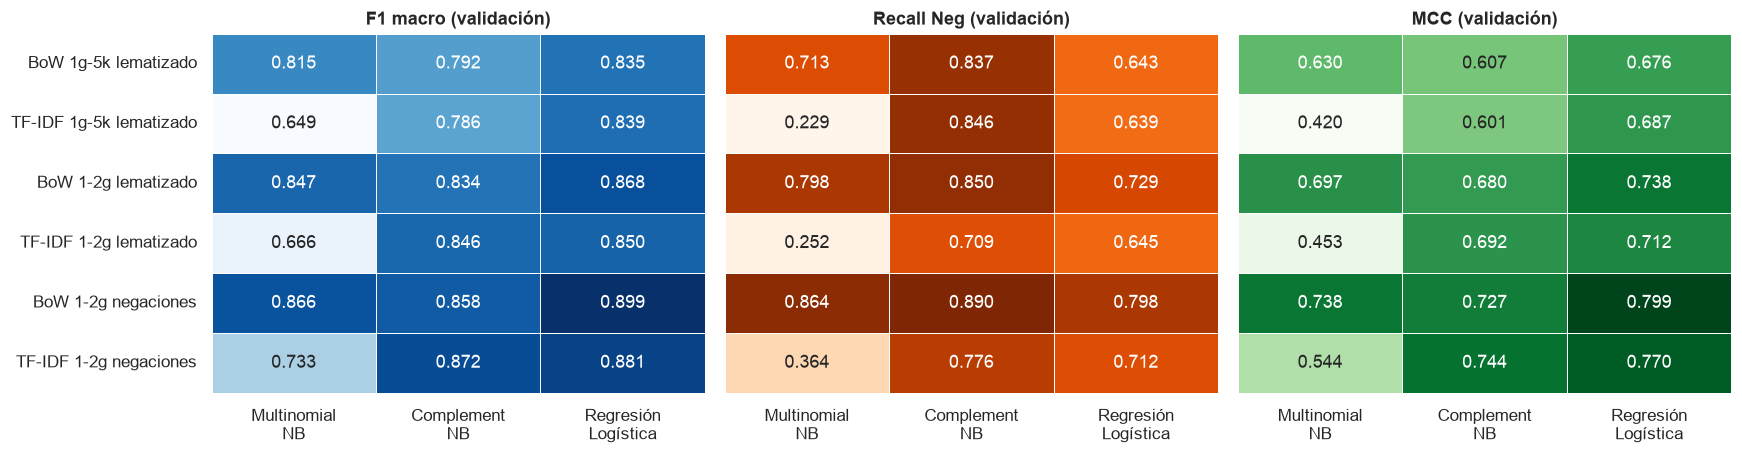

In [10]:
orden_rep = [f"{p} {c}" for c in CONFIG_VECT for p in ["BoW", "TF-IDF"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, metrica, cmap in zip(axes, ["F1 macro", "Recall Neg", "MCC"], ["Blues", "Oranges", "Greens"]):
    tabla = exp1.pivot(index="Representación", columns="Modelo", values=metrica).loc[orden_rep, FAMILIAS]
    sns.heatmap(tabla, annot=True, fmt=".3f", cmap=cmap, cbar=False, ax=ax, linewidths=.5)
    ax.set_title(f"{metrica} (validación)"); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels([m.replace(" ", "\n", 1) for m in FAMILIAS], rotation=0)
    if ax is not axes[0]:
        ax.set_yticklabels([])
plt.tight_layout(); guardar_fig("02_matriz_representacion_modelo"); plt.show()

### Análisis del experimento 1

**La representación pesa más que el modelo.** Con la representación de la Unidad 2 (TF-IDF 1-gramas/5k lematizado) el mejor F1 macro es 0,839; con la misma Regresión Logística pero sobre 1–2-gramas del texto **con negaciones** sube a 0,881 (TF-IDF) y 0,899 (BoW). Si se excluye la combinación mal emparejada MNB + TF-IDF (ver abajo), cambiar de modelo con la representación fija mueve el F1 macro entre 1 y 5 centésimas, mientras que cambiar la representación con el modelo fijo lo mueve entre 6 y 9 centésimas (LR: 0,835 → 0,899; CNB: 0,786 → 0,872).

Tres efectos se suman:
1. **Bigramas**: pasar de 1-gramas a 1–2-gramas mejora a todos los modelos (LR: 0,839 → 0,850 con TF-IDF; MNB BoW: 0,815 → 0,847), porque capturan expresiones como *highly recommend* o *waste money*.
2. **Conservar negaciones y palabras funcionales**: con la misma configuración de bigramas, usar el texto con negaciones en vez del lematizado aumenta el F1 macro de LR de 0,850 a 0,881 (TF-IDF) y su recall negativo de 0,645 a 0,712. Es la mejora individual más grande: la eliminación de stopwords de la Unidad 2 borraba justamente la información que invierte la polaridad.
3. **Vocabulario mayor**: 200.000 términos frente a 5.000 permiten representar n-gramas poco frecuentes pero muy discriminativos.

**Integración representación–modelo.**
- **Multinomial NB necesita conteos**: con BoW funciona razonablemente (F1 0,866 con negaciones), pero con TF-IDF colapsa (recall negativo 0,23–0,36). Con pesos TF-IDF normalizados, las "pseudo-frecuencias" de ambas clases quedan comprimidas y el *prior* de la clase mayoritaria (84 % positivas) domina la decisión. Es un ejemplo claro de **desconexión entre representación y supuestos del modelo**.
- **Complement NB** corrige ese sesgo: al estimar cada clase con los documentos de la otra, es mucho menos sensible al desbalance y alcanza el mayor recall negativo de la tabla (0,85–0,89), aunque a costa de precisión negativa.
- **Regresión Logística** es la más estable en todas las representaciones y la mejor en F1 macro y MCC en todas las filas. Con BoW sin escalar converge más lento (18,7 s frente a 2,8 s con TF-IDF), porque los conteos tienen escalas muy distintas entre documentos.

## 6. Experimento 2 — Ajuste de hiperparámetros (validación)

Sobre la configuración de texto ganadora del experimento 1 se ajustan:
- **NB** (MNB y CNB, con BoW y TF-IDF): suavizado $\alpha \in \{0{,}01; 0{,}03; 0{,}1; 0{,}3; 1\}$.
- **Regresión Logística** (TF-IDF): $C \in \{0{,}3; 1; 3; 10; 30\}$ × `class_weight` $\in$ {ninguno, balanceado}.

El criterio de selección es el **F1 macro en validación**.

In [11]:
mejor_exp1 = exp1.sort_values("F1 macro", ascending=False).iloc[0]
CFG_GANADORA = mejor_exp1["Configuración"]
print(f"Configuración de texto ganadora en el experimento 1: {CFG_GANADORA}")

filas = []
for familia in ["Multinomial NB", "Complement NB"]:
    for ponderacion in ["BoW", "TF-IDF"]:
        X_tr, X_va = REP[CFG_GANADORA][ponderacion]
        for alpha in [0.01, 0.03, 0.1, 0.3, 1.0]:
            _, _, _, m = entrenar_y_evaluar(familia, X_tr, y_sub, X_va, y_val, alpha=alpha)
            filas.append({"Modelo": familia, "Ponderación": ponderacion,
                          "Parámetros": {"alpha": alpha}, **m})

X_tr, X_va = REP[CFG_GANADORA]["TF-IDF"]
for C in [0.3, 1, 3, 10, 30]:
    for cw in [None, "balanced"]:
        _, _, _, m = entrenar_y_evaluar("Regresión Logística", X_tr, y_sub, X_va, y_val,
                                        C=C, class_weight=cw)
        filas.append({"Modelo": "Regresión Logística", "Ponderación": "TF-IDF",
                      "Parámetros": {"C": C, "class_weight": cw}, **m})
exp2 = pd.DataFrame(filas)

mejores = (exp2.sort_values("F1 macro", ascending=False)
               .groupby("Modelo", sort=False).head(1).reset_index(drop=True))
display(mejores[["Modelo", "Ponderación", "Parámetros"] + COLS_RESUMEN].round(4))
print("Rejilla completa de la Regresión Logística:")
display(exp2[exp2["Modelo"] == "Regresión Logística"][["Parámetros", "F1 macro", "Precision Neg", "Recall Neg", "MCC"]]
        .round(4).reset_index(drop=True))

Configuración de texto ganadora en el experimento 1: 1-2g negaciones


,Modelo,Ponderación,Parámetros,Accuracy,Accuracy balanceado,F1 macro,Precision Neg,Recall Neg,F1 Neg,Recall Pos,MCC,ROC-AUC,PR-AUC Neg,Log loss,Entrenamiento (s)
0,Regresión Logística,TF-IDF,"{'C': 30, 'class_weight': None}",0.9487,0.8867,0.8997,0.8659,0.7963,0.8296,0.9771,0.8005,0.9775,0.9127,0.1355,3.0880
1,Complement NB,TF-IDF,{'alpha': 1.0},0.9329,0.8689,0.8721,0.7924,0.7755,0.7839,0.9622,0.7443,0.9645,0.8522,0.2002,0.0693
2,Multinomial NB,BoW,{'alpha': 0.01},0.9288,0.8863,0.8708,0.7478,0.8243,0.7842,0.9483,0.7430,0.9472,0.8034,0.5809,0.2518


Rejilla completa de la Regresión Logística:


,Parámetros,F1 macro,Precision Neg,Recall Neg,MCC
0,"{'C': 0.3, 'class_weight': None}",0.8464,0.9162,0.6108,0.7135
1,"{'C': 0.3, 'class_weight': 'balanced'}",0.8704,0.6915,0.9158,0.7528
2,"{'C': 1, 'class_weight': None}",0.8813,0.9025,0.7118,0.7704
3,"{'C': 1, 'class_weight': 'balanced'}",0.8875,0.7330,0.9168,0.7827
4,"{'C': 3, 'class_weight': None}",0.8941,0.8905,0.7582,0.7920
5,"{'C': 3, 'class_weight': 'balanced'}",0.8990,0.7710,0.9044,0.8019
6,"{'C': 10, 'class_weight': None}",0.8986,0.8746,0.7850,0.7990
7,"{'C': 10, 'class_weight': 'balanced'}",0.8969,0.7717,0.8948,0.7971
8,"{'C': 30, 'class_weight': None}",0.8997,0.8659,0.7963,0.8005
9,"{'C': 30, 'class_weight': 'balanced'}",0.8782,0.7142,0.9086,0.7653


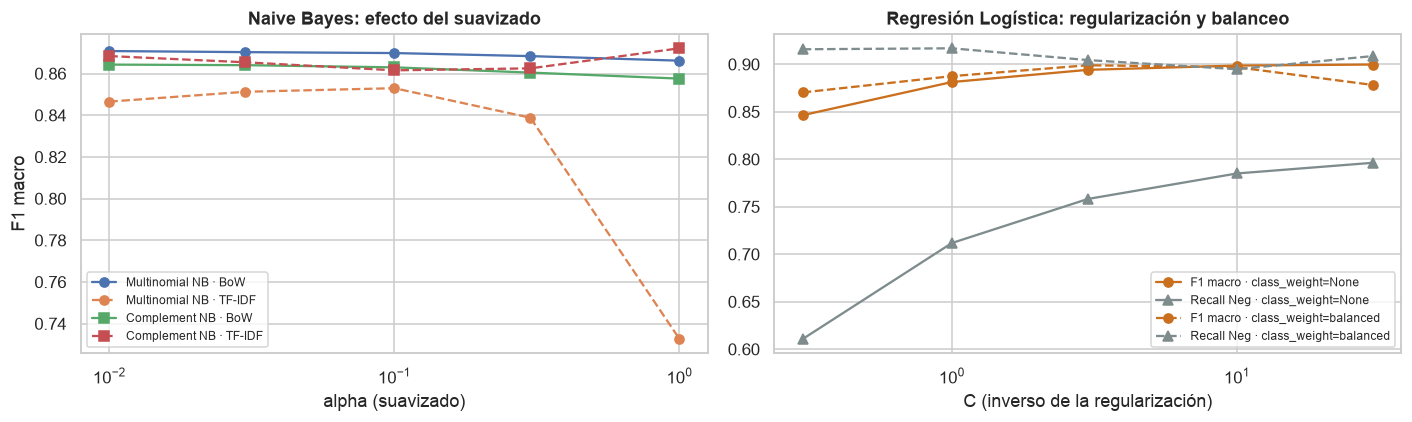

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for familia, marcador in [("Multinomial NB", "o"), ("Complement NB", "s")]:
    for ponderacion, estilo in [("BoW", "-"), ("TF-IDF", "--")]:
        d = exp2[(exp2["Modelo"] == familia) & (exp2["Ponderación"] == ponderacion)]
        axes[0].plot([p["alpha"] for p in d["Parámetros"]], d["F1 macro"], estilo,
                     marker=marcador, label=f"{familia} · {ponderacion}")
axes[0].set_xscale("log"); axes[0].set_xlabel("alpha (suavizado)"); axes[0].set_ylabel("F1 macro")
axes[0].set_title("Naive Bayes: efecto del suavizado"); axes[0].legend(fontsize=8)

d = exp2[exp2["Modelo"] == "Regresión Logística"]
for cw, estilo in [(None, "-"), ("balanced", "--")]:
    dd = d[[p["class_weight"] == cw for p in d["Parámetros"]]]
    Cs = [p["C"] for p in dd["Parámetros"]]
    axes[1].plot(Cs, dd["F1 macro"], estilo, marker="o", color=COLORES_MODELO["LR"],
                 label=f"F1 macro · class_weight={cw}")
    axes[1].plot(Cs, dd["Recall Neg"], estilo, marker="^", color="#7F8C8D",
                 label=f"Recall Neg · class_weight={cw}")
axes[1].set_xscale("log"); axes[1].set_xlabel("C (inverso de la regularización)")
axes[1].set_title("Regresión Logística: regularización y balanceo"); axes[1].legend(fontsize=8)
plt.tight_layout(); guardar_fig("03_hiperparametros"); plt.show()

### Análisis del experimento 2

- **Regresión Logística**: el mejor valor es $C = 30$ (regularización débil) sin balanceo de clases, con F1 macro de validación 0,8997, MCC 0,80 y PR-AUC negativa 0,913. Con 200.000 características y ~250.000 documentos hay datos suficientes para permitir coeficientes grandes sin sobreajustar; con $C = 0{,}3$ el F1 cae a 0,846 por exceso de regularización.
- `class_weight="balanced"` desplaza el equilibrio: sube el recall negativo a 0,89–0,92 pero baja la precisión negativa a 0,69–0,77. Su mejor variante ($C = 3$, F1 0,8990) queda prácticamente empatada con la elegida. Se prefiere la versión sin balanceo porque entrega probabilidades sin distorsionar y deja el equilibrio precision/recall al **umbral** (experimento 3), que es un ajuste más fino y explícito.
- **Naive Bayes**: el mejor es **Complement NB + TF-IDF con α = 1** (F1 0,872), prácticamente empatado con Multinomial NB + BoW con α = 0,01 (F1 0,871). MNB prefiere poco suavizado porque con 200.000 términos un α grande "aplana" las probabilidades de los n-gramas raros pero informativos.
- La diferencia entre la mejor LR y el mejor NB (≈0,028 en F1 macro, ≈0,057 en MCC) se mantiene tras el ajuste: no es un problema de hiperparámetros, sino de la capacidad de cada modelo.

## 7. Experimento 3 — Umbral de decisión (validación)

Por defecto se predice *Positiva* si $P(\text{positiva}) \ge 0{,}5$. Con clases desbalanceadas ese punto no tiene por qué maximizar el F1 macro. Se busca el umbral óptimo **en validación** para el mejor NB y la mejor LR; el umbral se aplicará después, sin cambios, al conjunto de prueba.

NB (Complement NB, TF-IDF, {'alpha': 1.0}): umbral óptimo = 0.49 | F1 macro val = 0.8724 (con 0,5: 0.8721)


LR (Regresión Logística, TF-IDF, {'C': 30, 'class_weight': None}): umbral óptimo = 0.62 | F1 macro val = 0.9025 (con 0,5: 0.8997)


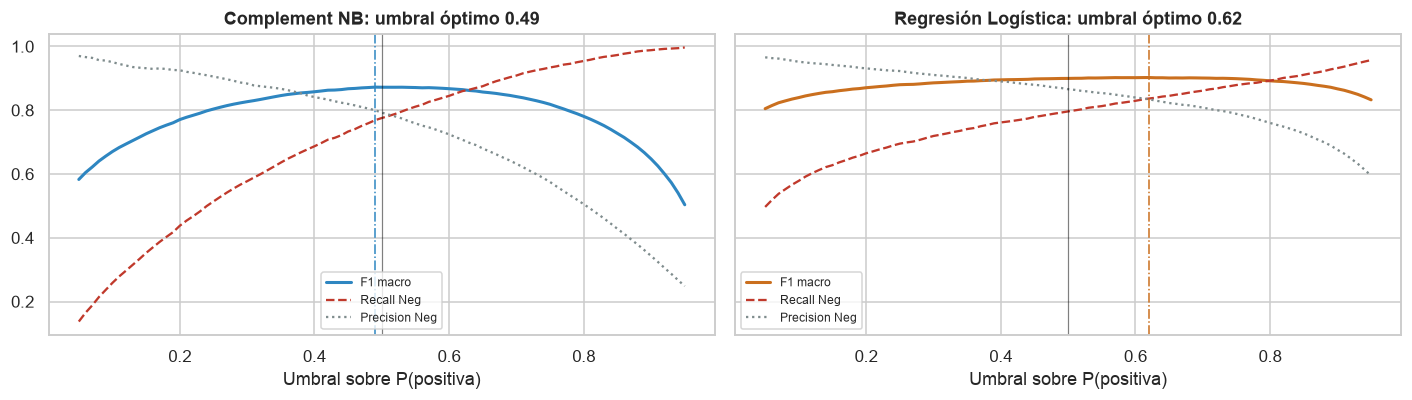

In [13]:
mejor_nb = (mejores[mejores["Modelo"].isin(["Multinomial NB", "Complement NB"])]
            .sort_values("F1 macro", ascending=False).iloc[0])
mejor_lr = mejores[mejores["Modelo"] == "Regresión Logística"].iloc[0]

SELECCION = {
    "NB": dict(familia=mejor_nb["Modelo"], ponderacion=mejor_nb["Ponderación"],
               params=mejor_nb["Parámetros"]),
    "LR": dict(familia="Regresión Logística", ponderacion="TF-IDF",
               params=mejor_lr["Parámetros"]),
}

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
curvas_umbral = {}
for clave, s in SELECCION.items():
    X_tr, X_va = REP[CFG_GANADORA][s["ponderacion"]]
    _, prob_val, _, _ = entrenar_y_evaluar(s["familia"], X_tr, y_sub, X_va, y_val, **s["params"])
    f1s = [f1_score(y_val, (prob_val >= u).astype(int), average="macro") for u in umbrales]
    rec_neg = [recall_score(y_val, (prob_val >= u).astype(int), pos_label=0) for u in umbrales]
    prec_neg = [precision_score(y_val, (prob_val >= u).astype(int), pos_label=0, zero_division=0)
                for u in umbrales]
    s["umbral"] = float(umbrales[int(np.argmax(f1s))])
    curvas_umbral[clave] = (f1s, rec_neg, prec_neg)
    print(f"{clave} ({s['familia']}, {s['ponderacion']}, {s['params']}): "
          f"umbral óptimo = {s['umbral']:.2f} | F1 macro val = {max(f1s):.4f} "
          f"(con 0,5: {f1s[list(umbrales).index(0.5)]:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (clave, (f1s, rec_neg, prec_neg)) in zip(axes, curvas_umbral.items()):
    ax.plot(umbrales, f1s, label="F1 macro", color=COLORES_MODELO[clave], lw=2)
    ax.plot(umbrales, rec_neg, label="Recall Neg", color=PALETA_SENT[0], ls="--")
    ax.plot(umbrales, prec_neg, label="Precision Neg", color="#7F8C8D", ls=":")
    ax.axvline(0.5, color="black", lw=.8, alpha=.5)
    ax.axvline(SELECCION[clave]["umbral"], color=COLORES_MODELO[clave], lw=1, ls="-.")
    ax.set_title(f"{SELECCION[clave]['familia']}: umbral óptimo {SELECCION[clave]['umbral']:.2f}")
    ax.set_xlabel("Umbral sobre P(positiva)"); ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("04_umbral"); plt.show()

### Análisis del experimento 3

- Para la **Regresión Logística** el umbral óptimo es **0,62**: exigir más seguridad para declarar *Positiva* recupera reseñas negativas que antes quedaban por debajo de 0,5. El F1 macro de validación pasa de 0,8997 a 0,9025.
- Para **Complement NB** el óptimo es 0,49, prácticamente el umbral por defecto (ganancia de 0,0003): CNB ya incorpora la corrección por desbalance en su estimación.
- Las curvas muestran el **intercambio precision–recall** de la clase negativa: subir el umbral aumenta el recall negativo y reduce su precisión. El umbral óptimo de F1 macro equilibra ambos; si el caso de negocio priorizara no perder quejas, se podría elegir un umbral mayor.

## 8. Curva de aprendizaje: ¿cuántos datos necesita cada modelo?

Se entrena con fracciones crecientes del subentrenamiento (misma representación) y se mide el F1 macro en validación. Es un experimento clásico para comparar un modelo **generativo** (NB) con uno **discriminativo** (LR).

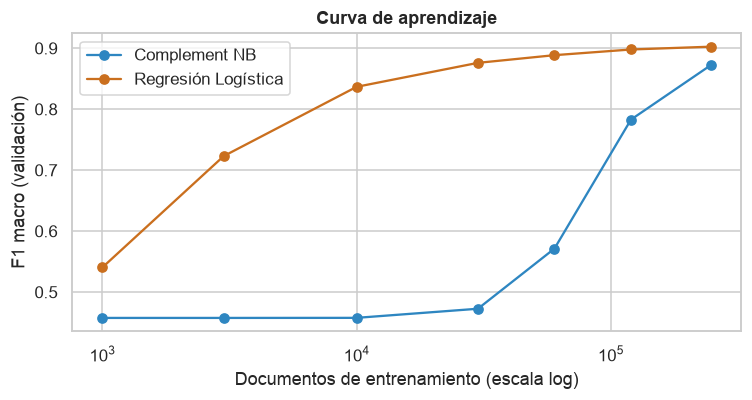

Modelo,LR,NB
n,,
1000,0.5405,0.4576
3000,0.7230,0.4576
10000,0.8367,0.4577
30000,0.8760,0.4727
60000,0.8886,0.5714
120000,0.8979,0.7829
247604,0.9025,0.8724


In [14]:
rng = np.random.default_rng(SEMILLA)
orden = rng.permutation(len(y_sub))
tamanos = [1_000, 3_000, 10_000, 30_000, 60_000, 120_000, len(y_sub)]
filas = []
for n in tamanos:
    sel = np.sort(orden[:n])
    for clave, s in SELECCION.items():
        X_tr, X_va = REP[CFG_GANADORA][s["ponderacion"]]
        _, _, _, m = entrenar_y_evaluar(s["familia"], X_tr[sel], y_sub[sel], X_va, y_val,
                                        umbral=s["umbral"], **s["params"])
        filas.append({"n": n, "Modelo": clave, "F1 macro": m["F1 macro"], "Recall Neg": m["Recall Neg"]})
curva = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(7, 3.8))
for clave in SELECCION:
    d = curva[curva["Modelo"] == clave]
    ax.plot(d["n"], d["F1 macro"], marker="o", color=COLORES_MODELO[clave],
            label=f"{SELECCION[clave]['familia']}")
ax.set_xscale("log"); ax.set_xlabel("Documentos de entrenamiento (escala log)")
ax.set_ylabel("F1 macro (validación)"); ax.set_title("Curva de aprendizaje"); ax.legend()
plt.tight_layout(); guardar_fig("05_curva_aprendizaje"); plt.show()
display(curva.pivot(index="n", columns="Modelo", values="F1 macro").round(4))

### Análisis de la curva de aprendizaje

- La **Regresión Logística** aprende rápido: con 10.000 reseñas ya alcanza F1 macro 0,84 (igual que la línea base de la Unidad 2 entrenada con 291.000) y sigue mejorando de forma logarítmica hasta 0,90.
- **Complement NB con α = 1 y 200.000 términos** necesita muchos más datos: con menos de 30.000 reseñas predice prácticamente todo como *Positiva* (F1 ≈ 0,46, igual al clasificador trivial) y con 60.000 apenas llega a 0,57. Con pocos documentos, el suavizado α = 1 sobre 200.000 n-gramas domina los conteos reales y los pesos de ambas clases quedan casi iguales. Esto matiza la idea habitual de que NB "aprende con menos datos": esa ventaja depende de que el suavizado y el tamaño del vocabulario sean acordes al volumen de datos.
- Ninguna curva se ha saturado del todo, lo que sugiere que más datos (o mejores representaciones) aún aportarían.

In [15]:
# Liberar memoria de las matrices de validación antes del entrenamiento final
del REP; gc.collect();

## 9. Entrenamiento final y evaluación en el conjunto de prueba

Con todas las decisiones ya tomadas en validación, se reajustan los vectorizadores y los modelos con el **entrenamiento completo (291.299 reseñas)** y se evalúan **una sola vez** sobre las 72.825 reseñas de prueba. Se comparan:

1. **Línea base U2**: Regresión Logística + TF-IDF 1-gramas/5k sobre texto lematizado (configuración por defecto, reportada previamente).
2. **NB básico**: Multinomial NB + BoW 1-gramas/5k lematizado (la combinación "de libro" de NB).
3. **Mejor NB** (representación, variante y $\alpha$ elegidos en validación), con umbral 0,5 y con umbral ajustado.
4. **Mejor Regresión Logística** (representación, $C$ y `class_weight` elegidos en validación), con umbral 0,5 y con umbral ajustado.

In [16]:
t0 = time.time()
REP_FINAL = {"1g-5k lematizado": vectorizar("1g-5k lematizado", idx_train, idx_test)}
if CFG_GANADORA != "1g-5k lematizado":
    REP_FINAL[CFG_GANADORA] = vectorizar(CFG_GANADORA, idx_train, idx_test)
print(f"Vectorización final en {time.time() - t0:.1f} s")

ESPEC_FINAL = [
    ("Línea base U2 · LR + TF-IDF 5k", "Base", "1g-5k lematizado", "TF-IDF", "Regresión Logística", {}, 0.5),
    ("NB básico · MNB + BoW 5k", "NB", "1g-5k lematizado", "BoW", "Multinomial NB", {}, 0.5),
    (f"Mejor NB · {SELECCION['NB']['familia']} (u=0.50)", "NB", CFG_GANADORA,
     SELECCION["NB"]["ponderacion"], SELECCION["NB"]["familia"], SELECCION["NB"]["params"], 0.5),
    (f"Mejor NB · {SELECCION['NB']['familia']} (u={SELECCION['NB']['umbral']:.2f})", "NB", CFG_GANADORA,
     SELECCION["NB"]["ponderacion"], SELECCION["NB"]["familia"], SELECCION["NB"]["params"], SELECCION["NB"]["umbral"]),
    ("Mejor LR (u=0.50)", "LR", CFG_GANADORA, "TF-IDF", "Regresión Logística", SELECCION["LR"]["params"], 0.5),
    (f"Mejor LR (u={SELECCION['LR']['umbral']:.2f})", "LR", CFG_GANADORA, "TF-IDF",
     "Regresión Logística", SELECCION["LR"]["params"], SELECCION["LR"]["umbral"]),
]

FINAL = {}
filas = []
cache_modelos = {}
for nombre, tipo, cfg, pond, familia, params, umbral in ESPEC_FINAL:
    X_tr, X_te = REP_FINAL[cfg][pond]
    clave_cache = (cfg, pond, familia, str(params))
    if clave_cache not in cache_modelos:
        modelo, prob, _, m_base = entrenar_y_evaluar(familia, X_tr, y_train, X_te, y_test, **params)
        cache_modelos[clave_cache] = (modelo, prob, m_base)
    modelo, prob, m_base = cache_modelos[clave_cache]
    pred = (prob >= umbral).astype(int)
    m = calcular_metricas(y_test, pred, prob)
    m["Entrenamiento (s)"] = m_base["Entrenamiento (s)"]
    FINAL[nombre] = dict(tipo=tipo, cfg=cfg, pond=pond, familia=familia, modelo=modelo,
                         prob=prob, pred=pred, umbral=umbral)
    filas.append({"Modelo": nombre, "Representación": f"{pond} {cfg}", **m})

resultados_test = pd.DataFrame(filas).set_index("Modelo")
display(resultados_test[["Representación"] + COLS_RESUMEN].round(4))

Vectorización final en 36.9 s


,Representación,Accuracy,Accuracy balanceado,F1 macro,Precision Neg,Recall Neg,F1 Neg,Recall Pos,MCC,ROC-AUC,PR-AUC Neg,Log loss,Entrenamiento (s)
Modelo,,,,,,,,,,,,,
Línea base U2 · LR + TF-IDF 5k,TF-IDF 1g-5k lematizado,0.9233,0.8095,0.8400,0.8287,0.6436,0.7246,0.9753,0.6881,0.9509,0.8262,0.1925,1.1212
NB básico · MNB + BoW 5k,BoW 1g-5k lematizado,0.8977,0.8192,0.8113,0.6637,0.7049,0.6837,0.9336,0.6231,0.9184,0.6980,0.3833,0.0672
Mejor NB · Complement NB (u=0.50),TF-IDF 1-2g negaciones,0.9299,0.8780,0.8702,0.7629,0.8025,0.7822,0.9536,0.7408,0.9636,0.8489,0.2091,0.2300
Mejor NB · Complement NB (u=0.49),TF-IDF 1-2g negaciones,0.9300,0.8749,0.8696,0.7676,0.7945,0.7808,0.9552,0.7393,0.9636,0.8489,0.2091,0.2300
Mejor LR (u=0.50),TF-IDF 1-2g negaciones,0.9510,0.8918,0.9044,0.8724,0.8054,0.8376,0.9781,0.8097,0.9780,0.9150,0.1379,7.3294
Mejor LR (u=0.62),TF-IDF 1-2g negaciones,0.9503,0.9052,0.9058,0.8426,0.8396,0.8411,0.9708,0.8116,0.9780,0.9150,0.1379,7.3294


In [17]:
NOMBRE_BASE = ESPEC_FINAL[0][0]
NOMBRE_NB = ESPEC_FINAL[3][0]
NOMBRE_LR = ESPEC_FINAL[5][0]

print("=" * 70)
for nombre in [NOMBRE_BASE, ESPEC_FINAL[1][0], NOMBRE_NB, NOMBRE_LR]:
    print(f"\n{nombre}")
    print(classification_report(y_test, FINAL[nombre]["pred"], target_names=NOMBRES_CLASES, digits=4))


Línea base U2 · LR + TF-IDF 5k
              precision    recall  f1-score   support

    Negativa     0.8287    0.6436    0.7246     11421
    Positiva     0.9364    0.9753    0.9554     61404

    accuracy                         0.9233     72825
   macro avg     0.8826    0.8095    0.8400     72825
weighted avg     0.9195    0.9233    0.9192     72825


NB básico · MNB + BoW 5k
              precision    recall  f1-score   support

    Negativa     0.6637    0.7049    0.6837     11421
    Positiva     0.9445    0.9336    0.9390     61404

    accuracy                         0.8977     72825
   macro avg     0.8041    0.8192    0.8113     72825
weighted avg     0.9004    0.8977    0.8989     72825


Mejor NB · Complement NB (u=0.49)
              precision    recall  f1-score   support

    Negativa     0.7676    0.7945    0.7808     11421
    Positiva     0.9615    0.9552    0.9584     61404

    accuracy                         0.9300     72825
   macro avg     0.8645    0.8749  

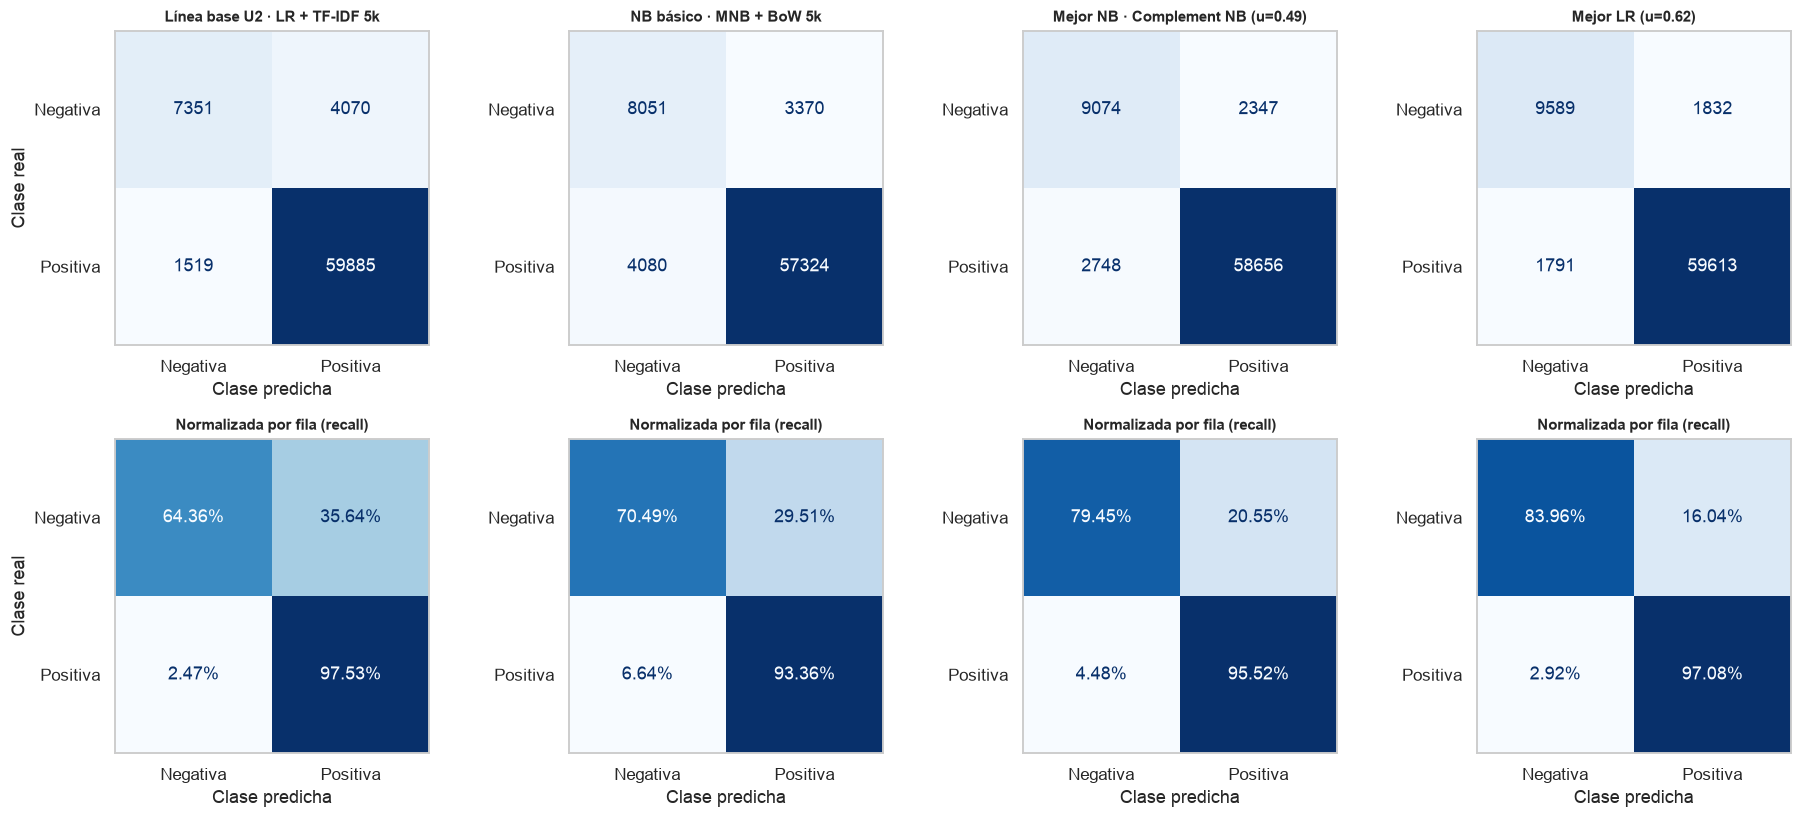

Línea base U2 · LR + TF-IDF 5k                Neg→Pos (negativas no detectadas):  4,070 | Pos→Neg (falsas alarmas):  1,519
NB básico · MNB + BoW 5k                      Neg→Pos (negativas no detectadas):  3,370 | Pos→Neg (falsas alarmas):  4,080
Mejor NB · Complement NB (u=0.49)             Neg→Pos (negativas no detectadas):  2,347 | Pos→Neg (falsas alarmas):  2,748
Mejor LR (u=0.62)                             Neg→Pos (negativas no detectadas):  1,832 | Pos→Neg (falsas alarmas):  1,791


In [18]:
modelos_cm = [NOMBRE_BASE, ESPEC_FINAL[1][0], NOMBRE_NB, NOMBRE_LR]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.6))
for j, nombre in enumerate(modelos_cm):
    for i, (normalizar, fmt) in enumerate([(None, "d"), ("true", ".2%")]):
        ConfusionMatrixDisplay.from_predictions(
            y_test, FINAL[nombre]["pred"], labels=[0, 1], display_labels=NOMBRES_CLASES,
            normalize=normalizar, values_format=fmt, cmap="Blues", colorbar=False, ax=axes[i, j])
        axes[i, j].set_title(nombre if i == 0 else "Normalizada por fila (recall)",
                             fontsize=9.5)
        axes[i, j].grid(False)
        axes[i, j].set_xlabel("Clase predicha"); axes[i, j].set_ylabel("Clase real")
        if j > 0:
            axes[i, j].set_ylabel("")
plt.tight_layout(); guardar_fig("06_matrices_confusion"); plt.show()

for nombre in modelos_cm:
    tn, fp, fn, tp = confusion_matrix(y_test, FINAL[nombre]["pred"], labels=[0, 1]).ravel()
    print(f"{nombre:45s} Neg→Pos (negativas no detectadas): {fp:6,} | Pos→Neg (falsas alarmas): {fn:6,}")

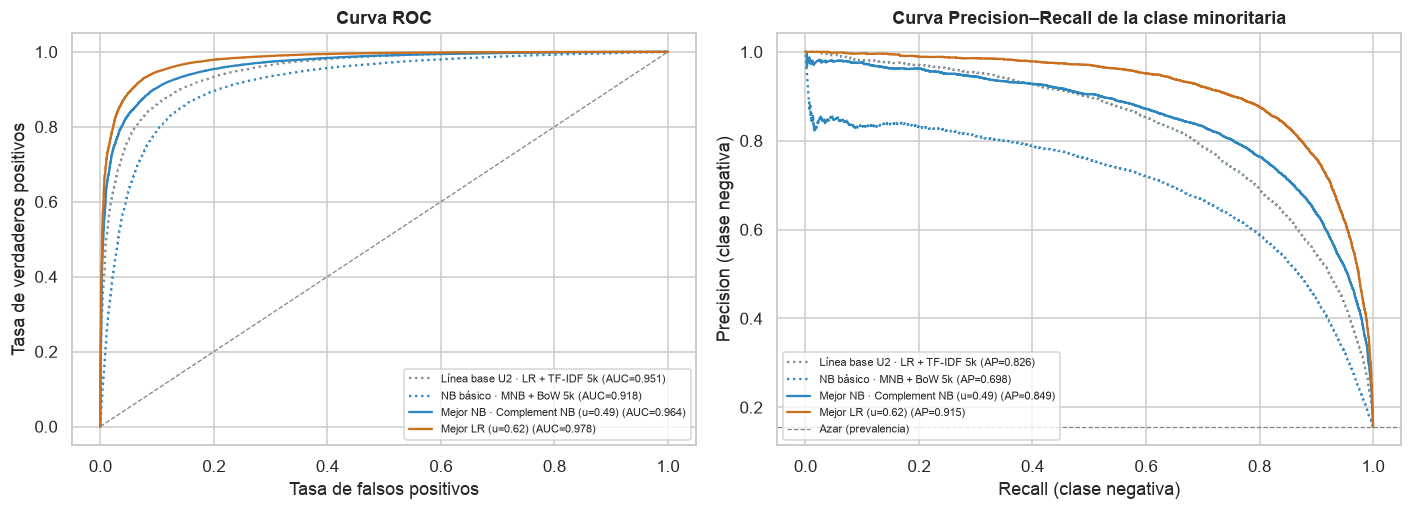

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
estilos = {NOMBRE_BASE: (COLORES_MODELO["Base"], ":"), ESPEC_FINAL[1][0]: (COLORES_MODELO["NB"], ":"),
           NOMBRE_NB: (COLORES_MODELO["NB"], "-"), NOMBRE_LR: (COLORES_MODELO["LR"], "-")}
for nombre, (color, ls) in estilos.items():
    prob = FINAL[nombre]["prob"]
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, ls=ls, label=f"{nombre} (AUC={roc_auc_score(y_test, prob):.3f})")
    prec, rec, _ = precision_recall_curve(1 - y_test, 1 - prob)
    ap = average_precision_score(1 - y_test, 1 - prob)
    axes[1].plot(rec, prec, color=color, ls=ls, label=f"{nombre} (AP={ap:.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=.8, ls="--")
axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curva ROC"); axes[0].legend(fontsize=7.5, loc="lower right")
axes[1].axhline((y_test == 0).mean(), color="grey", lw=.8, ls="--", label="Azar (prevalencia)")
axes[1].set_xlabel("Recall (clase negativa)"); axes[1].set_ylabel("Precision (clase negativa)")
axes[1].set_title("Curva Precision–Recall de la clase minoritaria"); axes[1].legend(fontsize=7.5, loc="lower left")
plt.tight_layout(); guardar_fig("07_roc_pr"); plt.show()

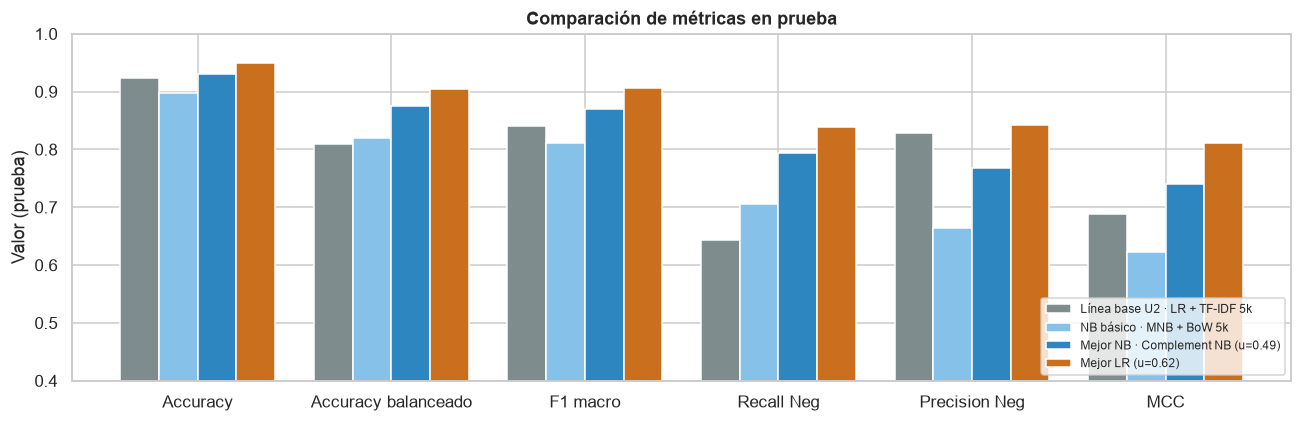

In [20]:
metricas_graf = ["Accuracy", "Accuracy balanceado", "F1 macro", "Recall Neg", "Precision Neg", "MCC"]
d = resultados_test.loc[modelos_cm, metricas_graf].T
ax = d.plot(kind="bar", figsize=(12, 4), width=.8,
            color=[COLORES_MODELO["Base"], "#85C1E9", COLORES_MODELO["NB"], COLORES_MODELO["LR"]])
ax.set_ylim(0.4, 1.0); ax.set_ylabel("Valor (prueba)"); ax.set_title("Comparación de métricas en prueba")
ax.legend(fontsize=8, loc="lower right"); plt.xticks(rotation=0)
plt.tight_layout(); guardar_fig("08_comparacion_metricas"); plt.show()

### 9.1 Incertidumbre y significancia estadística

- **Intervalos de confianza bootstrap (95 %)**: se remuestrea con reemplazo el conjunto de prueba 1.000 veces y se recalculan las métricas, para saber si las diferencias entre modelos son mayores que la variabilidad por muestreo.
- **Prueba de McNemar**: compara dos clasificadores sobre los mismos documentos usando solo los casos en que discrepan ($b$: acierta A y falla B; $c$: falla A y acierta B). $\chi^2 = (|b-c|-1)^2/(b+c)$.

In [21]:
def metricas_rapidas(y_real, y_pred):
    # F1 macro, recall negativo y accuracy a partir de la matriz de confusión (vectorizado)
    tp = ((y_real == 1) & (y_pred == 1)).sum(); tn = ((y_real == 0) & (y_pred == 0)).sum()
    fp = ((y_real == 0) & (y_pred == 1)).sum(); fn = ((y_real == 1) & (y_pred == 0)).sum()
    f1_pos = 2 * tp / (2 * tp + fp + fn); f1_neg = 2 * tn / (2 * tn + fn + fp)
    return (f1_pos + f1_neg) / 2, tn / (tn + fp), (tp + tn) / len(y_real)

rng = np.random.default_rng(SEMILLA)
B = 1000
muestras = rng.integers(0, len(y_test), size=(B, len(y_test)))
filas = []
for nombre in modelos_cm:
    pred = FINAL[nombre]["pred"]
    boot = np.array([metricas_rapidas(y_test[s], pred[s]) for s in muestras])
    for k, metrica in enumerate(["F1 macro", "Recall Neg", "Accuracy"]):
        filas.append({"Modelo": nombre, "Métrica": metrica,
                      "Estimación": metricas_rapidas(y_test, pred)[k],
                      "IC 95% inf": np.percentile(boot[:, k], 2.5),
                      "IC 95% sup": np.percentile(boot[:, k], 97.5)})
ic = pd.DataFrame(filas)
display(ic.pivot(index="Modelo", columns="Métrica", values=["Estimación", "IC 95% inf", "IC 95% sup"])
          .round(4).loc[modelos_cm])

def mcnemar(y_real, pred_a, pred_b):
    a_ok, b_ok = pred_a == y_real, pred_b == y_real
    b = int((a_ok & ~b_ok).sum()); c = int((~a_ok & b_ok).sum())
    estad = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, estad, chi2.sf(estad, df=1)

for a, b_ in [(NOMBRE_LR, NOMBRE_NB), (NOMBRE_LR, NOMBRE_BASE), (NOMBRE_NB, ESPEC_FINAL[1][0])]:
    b, c, est, p = mcnemar(y_test, FINAL[a]["pred"], FINAL[b_]["pred"])
    print(f"McNemar  {a}  vs  {b_}\n   solo acierta el 1.º: {b:,} | solo acierta el 2.º: {c:,} | "
          f"chi2 = {est:,.1f} | p = {p:.2e}")

Estimación                     IC 95% inf  \
Métrica                             Accuracy F1 macro Recall Neg   Accuracy   
Modelo                                                                        
Línea base U2 · LR + TF-IDF 5k        0.9233   0.8400     0.6436     0.9213   
NB básico · MNB + BoW 5k              0.8977   0.8113     0.7049     0.8953   
Mejor NB · Complement NB (u=0.49)     0.9300   0.8696     0.7945     0.9281   
Mejor LR (u=0.62)                     0.9503   0.9058     0.8396     0.9487   

                                                      IC 95% sup           \
Métrica                           F1 macro Recall Neg   Accuracy F1 macro   
Modelo                                                                      
Línea base U2 · LR + TF-IDF 5k      0.8360     0.6342     0.9251   0.8438   
NB básico · MNB + BoW 5k            0.8074     0.6970     0.8999   0.8150   
Mejor NB · Complement NB (u=0.49)   0.8661     0.7872     0.9318   0.8728   
Mejor LR (u=0.62)                   0.9029     0.8325     0.9518   0.9087   

                                              
Métrica                           Recall Neg  
Modelo                                        
Línea base U2 · LR + TF-IDF 5k        0.6524  
NB básico · MNB + BoW 5k              0.7128  
Mejor NB · Complement NB (u=0.49)     0.8015  
Mejor LR (u=0.62)                     0.8462

McNemar  Mejor LR (u=0.62)  vs  Mejor NB · Complement NB (u=0.49)
   solo acierta el 1.º: 2,758 | solo acierta el 2.º: 1,286 | chi2 = 535.1 | p = 2.22e-118
McNemar  Mejor LR (u=0.62)  vs  Línea base U2 · LR + TF-IDF 5k
   solo acierta el 1.º: 3,301 | solo acierta el 2.º: 1,335 | chi2 = 832.9 | p = 3.84e-183
McNemar  Mejor NB · Complement NB (u=0.49)  vs  NB básico · MNB + BoW 5k
   solo acierta el 1.º: 3,542 | solo acierta el 2.º: 1,187 | chi2 = 1,171.8 | p = 8.31e-257


### Análisis de la evaluación en prueba

**Resultado principal.** La mejor Regresión Logística (TF-IDF 1–2-gramas con negaciones, C = 30, umbral 0,62) obtiene en prueba **accuracy 0,950, F1 macro 0,906, MCC 0,812, ROC-AUC 0,978 y PR-AUC negativa 0,915**. Frente a la línea base de la Unidad 2 (F1 macro 0,840, MCC 0,688):
- El **recall negativo** pasa de 0,644 a 0,840: las negativas no detectadas bajan de **4.070 a 1.832** (−55 %), mientras que las falsas alarmas apenas suben (1.519 → 1.791).
- La precisión y el recall negativos quedan **equilibrados** (0,843 / 0,840), cuando antes había una brecha de 18 puntos.

**Naive Bayes vs. Regresión Logística.**
- El NB básico (MNB + BoW 5k) es el modelo más débil (F1 0,811), pero con la representación mejorada Complement NB alcanza F1 0,870 y supera a la línea base de LR: **una buena representación hace competitivo incluso al modelo más simple**.
- Aun así, LR supera a NB en todas las métricas de ranking y calibración: ROC-AUC 0,978 vs. 0,964, PR-AUC negativa 0,915 vs. 0,849 y log loss 0,138 vs. 0,209. Al no asumir independencia entre términos, LR reparte el peso entre n-gramas correlacionados (*not*, *not good*, *not worth*) en vez de contarlos varias veces.
- NB es ~80 veces más rápido de entrenar (0,08 s vs. 6,9 s), lo que lo hace atractivo como primera aproximación o con recursos limitados.

**Significancia.** Los intervalos bootstrap del 95 % no se solapan (F1 macro LR [0,903; 0,909] vs. NB [0,866; 0,873] vs. línea base [0,836; 0,844]) y McNemar rechaza la igualdad en las tres comparaciones (p < 10⁻¹¹⁸): las diferencias no se deben al azar del muestreo.

**Accuracy engañoso.** El accuracy de la línea base (0,923) parece cercano al del mejor modelo (0,950), pero el MCC muestra una diferencia mucho mayor (0,688 vs. 0,812). Con 84 % de positivas, el accuracy subestima las diferencias en la clase minoritaria.

## 10. Estabilidad: validación cruzada estratificada (5 pliegues)

Para comprobar que los resultados no dependen de una partición afortunada, se repite el entrenamiento de las configuraciones finales en 5 pliegues del conjunto de entrenamiento. En **cada pliegue** el vectorizador se ajusta solo con los 4 pliegues de entrenamiento (sin fuga de información).

In [22]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
t0 = time.time()
for k, (tr, va) in enumerate(skf.split(idx_train, y_train), start=1):
    rep_k = vectorizar(CFG_GANADORA, idx_train[tr], idx_train[va])
    for clave, s in SELECCION.items():
        X_tr, X_va = rep_k[s["ponderacion"]]
        _, _, _, m = entrenar_y_evaluar(s["familia"], X_tr, y_train[tr], X_va, y_train[va],
                                        umbral=s["umbral"], **s["params"])
        filas.append({"Pliegue": k, "Modelo": s["familia"], **m})
    del rep_k; gc.collect()
cv5 = pd.DataFrame(filas)
print(f"Validación cruzada completada en {time.time() - t0:.0f} s")
resumen_cv = cv5.groupby("Modelo")[["Accuracy", "F1 macro", "Recall Neg", "MCC", "ROC-AUC"]].agg(["mean", "std"])
display(resumen_cv.round(4))

Validación cruzada completada en 147 s


Accuracy         F1 macro         Recall Neg          \
                        mean     std     mean     std       mean     std   
Modelo                                                                     
Complement NB         0.9317  0.0013   0.8671  0.0024     0.7482  0.0034   
Regresión Logística   0.9482  0.0009   0.9024  0.0017     0.8382  0.0045   

                        MCC         ROC-AUC          
                       mean     std    mean     std  
Modelo                                               
Complement NB        0.7349  0.0049  0.9632  0.0012  
Regresión Logística  0.8048  0.0033  0.9779  0.0005

### Análisis de estabilidad

En validación cruzada de 5 pliegues (vectorizador reajustado en cada pliegue) la Regresión Logística obtiene F1 macro **0,902 ± 0,002** y Complement NB **0,867 ± 0,002**, valores consistentes con los de prueba (0,906 y 0,870). Las desviaciones estándar son de milésimas y mucho menores que la diferencia entre modelos, de modo que la conclusión no depende de una partición concreta.

## 11. Interpretabilidad: ¿qué aprendió cada modelo?

- **Regresión Logística**: el coeficiente $w_j$ indica cuánto aumenta el log-odds de *Positiva* por cada unidad TF-IDF del término $j$.
- **Naive Bayes**: para cada término se calcula la diferencia de log-pesos entre clases, $\log \theta_{j,\text{pos}} - \log \theta_{j,\text{neg}}$, que es su contribución lineal a la decisión.

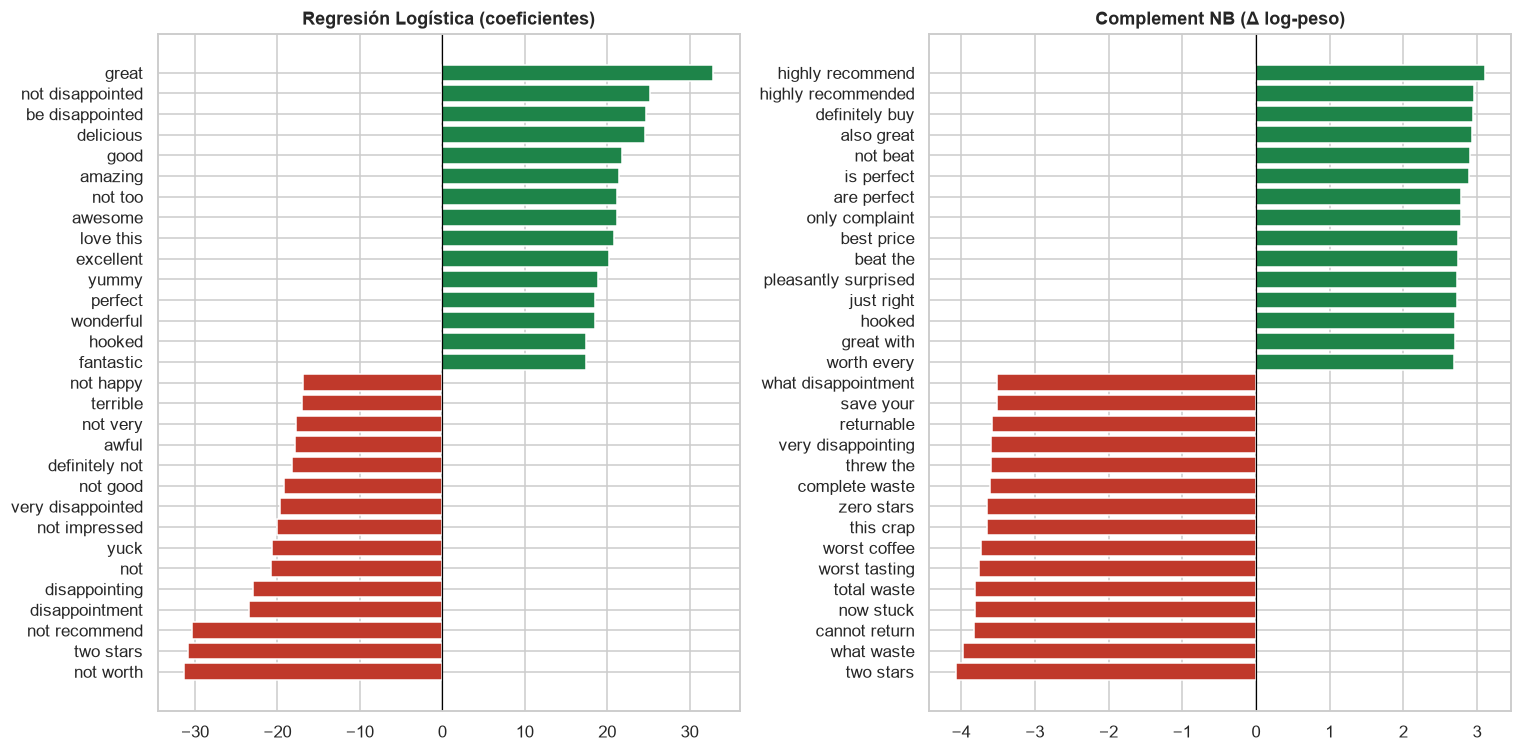

Términos con negación entre los 50 más negativos -> LR: 16 | NB: 5


In [23]:
def top_terminos(pesos, vocabulario, k=15):
    orden = np.argsort(pesos)
    return (pd.Series(pesos[orden[:k]], index=vocabulario[orden[:k]]),
            pd.Series(pesos[orden[-k:]], index=vocabulario[orden[-k:]]))

vocab = REP_FINAL[CFG_GANADORA]["vectorizador"].get_feature_names_out()
pesos_lr = FINAL[NOMBRE_LR]["modelo"].coef_[0]
flp = FINAL[NOMBRE_NB]["modelo"].feature_log_prob_
pesos_nb = flp[1] - flp[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, pesos, titulo in [(axes[0], pesos_lr, "Regresión Logística (coeficientes)"),
                          (axes[1], pesos_nb, f"{SELECCION['NB']['familia']} (Δ log-peso)")]:
    neg, pos = top_terminos(pesos, vocab)
    serie = pd.concat([neg, pos])
    ax.barh(serie.index, serie.values, color=[PALETA_SENT[0]] * len(neg) + [PALETA_SENT[1]] * len(pos))
    ax.axvline(0, color="black", lw=.8); ax.set_title(titulo)
plt.tight_layout(); guardar_fig("09_terminos_influyentes"); plt.show()

# ¿Cuántos de los términos más negativos contienen una negación?
neg_lr, _ = top_terminos(pesos_lr, vocab, k=50)
neg_nb, _ = top_terminos(pesos_nb, vocab, k=50)
negadores = r"\b(?:not|no|never|nothing|nor)\b"
print(f"Términos con negación entre los 50 más negativos -> LR: "
      f"{neg_lr.index.str.contains(negadores).sum()} | NB: {neg_nb.index.str.contains(negadores).sum()}")

### Análisis de interpretabilidad

- Los coeficientes de la **Regresión Logística** confirman el valor de conservar negaciones: entre sus 50 términos más negativos, 16 contienen una negación (*not worth, not recommend, not good, not impressed, definitely not*). Además el modelo aprende a **invertir polaridad**: *not disappointed* y *not too* ("not too sweet") tienen peso positivo, algo imposible con el texto lematizado sin stopwords.
- *be disappointed* aparece como positivo porque casi siempre va precedido de *will not* / *won't* ("you won't be disappointed"): los bigramas capturan parte del contexto, pero no todo, ya que el modelo solo ve pares de palabras adyacentes.
- **Complement NB** prioriza n-gramas muy específicos y poco frecuentes (*zero stars, complete waste, cannot return, highly recommend*). Al estimar cada término por separado, da mucho peso a expresiones raras pero casi exclusivas de una clase, mientras que LR reparte el peso entre términos correlacionados.
- *two stars* es uno de los términos más negativos en ambos modelos: algunos usuarios escriben su puntuación en el texto. No es fuga de información (la etiqueta se deriva de `Score`, no del texto), pero muestra que parte del rendimiento viene de pistas explícitas.

## 12. Análisis de errores

Se analiza **dónde** se equivoca el mejor modelo frente a la línea base: por puntuación original, por longitud de la reseña y por presencia de negaciones. Luego se leen ejemplos concretos usando el **texto original**.

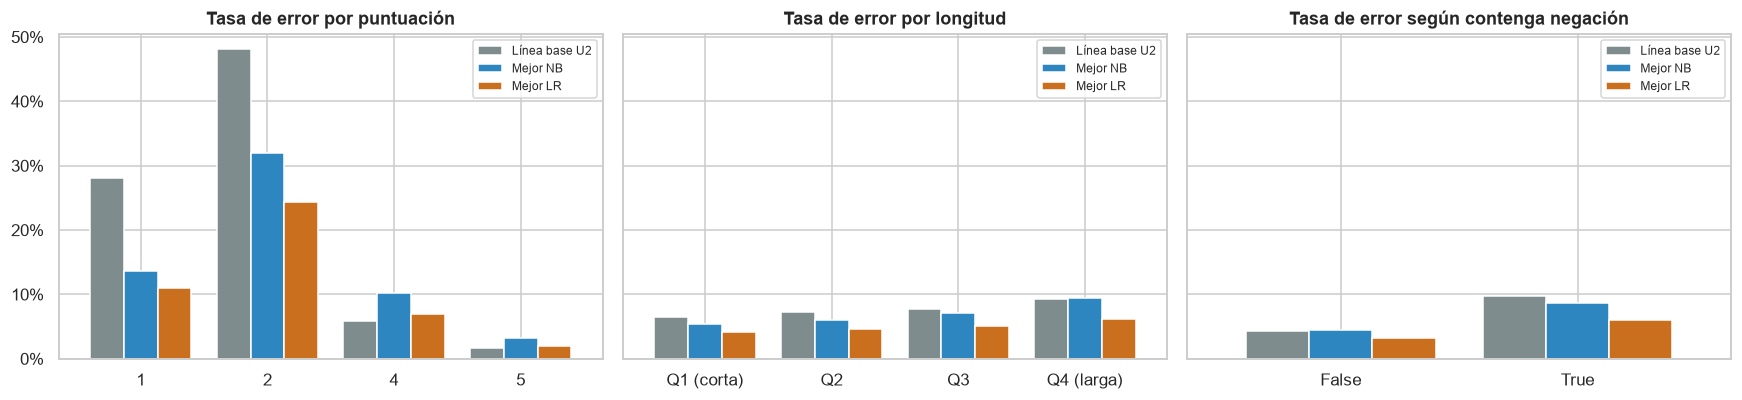

,Línea base U2,Mejor NB,Mejor LR
Score,,,
1,0.2816,0.1365,0.1106
2,0.4809,0.3203,0.2434
4,0.0579,0.1017,0.0699
5,0.0174,0.0321,0.0201


,Línea base U2,Mejor NB,Mejor LR
tiene_negacion,,,
False,0.0435,0.0443,0.0323
True,0.0976,0.0860,0.0607


In [24]:
df_test = df_bin.iloc[idx_test].reset_index(drop=True).copy()
df_test["n_palabras"] = df_test["Text"].str.split().str.len()
df_test["tiene_negacion"] = df_test["Text_negaciones"].str.contains(r"\b(?:not|no|never)\b", regex=True)
for nombre, alias in [(NOMBRE_BASE, "base"), (NOMBRE_NB, "nb"), (NOMBRE_LR, "lr")]:
    df_test[f"error_{alias}"] = FINAL[nombre]["pred"] != y_test
df_test["prob_lr"] = FINAL[NOMBRE_LR]["prob"]

df_test["Longitud"] = pd.qcut(df_test["n_palabras"], 4,
                              labels=["Q1 (corta)", "Q2", "Q3", "Q4 (larga)"])
cols_err = {"error_base": "Línea base U2", "error_nb": "Mejor NB", "error_lr": "Mejor LR"}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (var, titulo) in zip(axes, [("Score", "Tasa de error por puntuación"),
                                    ("Longitud", "Tasa de error por longitud"),
                                    ("tiene_negacion", "Tasa de error según contenga negación")]):
    t = df_test.groupby(var, observed=True)[list(cols_err)].mean().rename(columns=cols_err)
    t.plot(kind="bar", ax=ax, color=[COLORES_MODELO["Base"], COLORES_MODELO["NB"], COLORES_MODELO["LR"]], width=.8)
    ax.set_title(titulo); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("10_errores_por_grupo"); plt.show()

display(df_test.groupby("Score")[list(cols_err)].mean().rename(columns=cols_err).round(4))
display(df_test.groupby("tiene_negacion")[list(cols_err)].mean().rename(columns=cols_err).round(4))

In [25]:
pd.set_option("display.max_colwidth", 320)
errores = df_test[df_test["error_lr"]].copy()
errores["Texto (recortado)"] = errores["Text"].str.slice(0, 300)

print("Negativas con mayor confianza errónea (el modelo dijo 'Positiva'):")
display(errores[errores["Sentimiento"] == 0].nlargest(5, "prob_lr")[["Score", "prob_lr", "Texto (recortado)"]].round(3))
print("Positivas con mayor confianza errónea (el modelo dijo 'Negativa'):")
display(errores[errores["Sentimiento"] == 1].nsmallest(5, "prob_lr")[["Score", "prob_lr", "Texto (recortado)"]].round(3))

print("Reseñas que la línea base fallaba y el mejor modelo corrige (contienen negación):")
corregidas = df_test[df_test["error_base"] & ~df_test["error_lr"] & df_test["tiene_negacion"]]
display(corregidas.sample(4, random_state=SEMILLA)[["Score", "Text"]]
        .assign(Text=lambda d: d["Text"].str.slice(0, 260)))

Negativas con mayor confianza errónea (el modelo dijo 'Positiva'):


,Score,prob_lr,Texto (recortado)
30669,1,1.0,"I was first introduced to this product in New Orleans. When I cam home to Los Angeles, I couldn't find it in the stores and was so happy to find it. The product was reasonable, came quickly and it totally yummy. It also does the trick for me with heartburn and alleviates a scratchy throat."
70212,2,1.0,It arrived quickly & in good condition. It has good flavor. Nice product.
43740,1,1.0,Bisquick GF is easy to use. Pancakes and muffins are very<br />tasty. The product is quick and easy to use. It makes my day. Gram
63785,1,1.0,To expensive. but great product. Taste just the same as the bottled stuff and you can make it less sweet which is what I do.
31400,1,1.0,"As I stated above, this is a great product for cats. My four cats, some old some young, love it. Especially my 5 years old male tabby.<br /><br />And, the store shipping the product is really fast. Thank you...my cats George and Gracie thank you.<br />Carol Sheats"


Positivas con mayor confianza errónea (el modelo dijo 'Negativa'):


,Score,prob_lr,Texto (recortado)
65260,5,0.0,i was not happy with this item 0.85 oz is very small and i am so sory i did not take the time to recognize how small this item was i ordered the package of six and when i got it i was realy angry i think its useliss to sell products like this in such small quantities i would have done better if i ha
57674,5,0.0,"It wasn't what we wanted, so we returned it and got the ones we wanted."
63586,4,0.0,"When coffee was being ground I could tell the beans were old and dried out, not a good flavor or or even much of any flavor at all, save your money on this company.<br />Called company and they made restitution."
592,4,0.0,I ordered this from Liquid nation and what I received was not as described. First of all I didn't receive all different K-cup as promised. I had recieved multiple duplicates in my package as well as 9 that had expired last year. I also received one K-cup that was clearly punctured in multiple locati
19745,5,0.0,"Ordered coffee for a few months. Now I would not recommend it to my worst enemy. The coffee now has no aroma, is light brown and taste worse than ___________. (fill in the blank)"


Reseñas que la línea base fallaba y el mejor modelo corrige (contienen negación):


,Score,Text
20772,2,"I know these are supposed to be good for you but they are a little hard to get down without lots of liquid. Also, way too expensive. I don't think I will be buying them again."
45776,2,I was very skeptical when I ordered this as I don't usually order any type of food from this kind of site. I should have listen to my initial instinct. The candy arrived and it was basically unedible. I could not even chew it. It was hard as a rock. It fel
41003,2,I stick with the bears from the store after trying a bulk bag of these. They had an odd smell to them and they didn't have as much flavor as the Target brand or store bought brand. Spend the tiny bit more per bag and buy the ones in the store so you know the
50825,1,"Not tasty Not spicy<br />Just some bland mix of vegetables, you can make something better at home even if you are new to using the stove. Try Jyoti brand, i have to try it yet but based on reviews it should be better<br /><br />EDIT:<br /><br />Tried ""Jyoti"" a"


### Análisis de errores

- **Las reseñas de 2 y 4 estrellas concentran la dificultad**: la mejor LR falla el 24 % de las de 2 estrellas y el 7 % de las de 4, frente al 11 % de las de 1 y el 2 % de las de 5. Son opiniones moderadas o mixtas, cercanas a la frontera que se eliminó al excluir las de 3 estrellas. La mejora más grande frente a la línea base está justamente en las de 2 estrellas (48 % → 24 % de error).
- **Negaciones**: en reseñas que contienen *not/no/never* la tasa de error baja de 9,8 % (línea base) a 6,1 % (mejor LR), una reducción mayor que en las reseñas sin negación (4,4 % → 3,2 %). Es la evidencia directa de que preservar las negaciones resuelve parte del problema.
- **Ruido en las etiquetas**: varios de los errores "más seguros" no son fallos reales del modelo. Hay reseñas con 1 estrella y texto claramente elogioso ("*great product for cats… my four cats love it*") y reseñas con 5 estrellas que describen una mala experiencia ("*I would not recommend it to my worst enemy*"). Probablemente el usuario se equivocó al puntuar o escribió en un producto distinto. Ningún modelo basado en texto puede acertar estos casos, y marcan un **techo práctico** para el rendimiento.
- **Opiniones con contraste** ("*Too expensive. but great product*") siguen siendo difíciles: el modelo pondera palabras y bigramas, pero no sabe cuál parte de la oración domina el juicio global.

## 13. Robustez: textos repetidos entre entrenamiento y prueba

En la Unidad 2 se eliminaron duplicados por `UserId + Time + Text`, pero Amazon publica la misma reseña en variantes de un mismo producto con distinto usuario o fecha. Si un texto idéntico aparece en entrenamiento y en prueba, el modelo podría "recordarlo" e inflar las métricas. Se cuantifica y se reevalúa sin esos casos.

In [26]:
textos_train = set(df_bin["Text"].values[idx_train])
repetido = df_test["Text"].isin(textos_train).values
print(f"Reseñas de prueba cuyo texto exacto aparece en entrenamiento: {repetido.sum():,} "
      f"({repetido.mean():.2%})")

filas = []
for nombre in modelos_cm:
    for etiqueta, mascara in [("Prueba completa", np.ones_like(repetido)), ("Sin textos repetidos", ~repetido)]:
        m = calcular_metricas(y_test[mascara], FINAL[nombre]["pred"][mascara], FINAL[nombre]["prob"][mascara])
        filas.append({"Modelo": nombre, "Subconjunto": etiqueta, **{k: m[k] for k in ["Accuracy", "F1 macro", "Recall Neg", "MCC"]}})
display(pd.DataFrame(filas).pivot(index="Modelo", columns="Subconjunto").round(4).loc[modelos_cm])

Reseñas de prueba cuyo texto exacto aparece en entrenamiento: 93 (0.13%)


Accuracy                       \
Subconjunto                       Prueba completa Sin textos repetidos   
Modelo                                                                   
Línea base U2 · LR + TF-IDF 5k             0.9233               0.9232   
NB básico · MNB + BoW 5k                   0.8977               0.8977   
Mejor NB · Complement NB (u=0.49)          0.9300               0.9301   
Mejor LR (u=0.62)                          0.9503               0.9502   

                                         F1 macro                       \
Subconjunto                       Prueba completa Sin textos repetidos   
Modelo                                                                   
Línea base U2 · LR + TF-IDF 5k             0.8400               0.8399   
NB básico · MNB + BoW 5k                   0.8113               0.8114   
Mejor NB · Complement NB (u=0.49)          0.8696               0.8697   
Mejor LR (u=0.62)                          0.9058               0.9058   

                                       Recall Neg                       \
Subconjunto                       Prueba completa Sin textos repetidos   
Modelo                                                                   
Línea base U2 · LR + TF-IDF 5k             0.6436               0.6436   
NB básico · MNB + BoW 5k                   0.7049               0.7048   
Mejor NB · Complement NB (u=0.49)          0.7945               0.7945   
Mejor LR (u=0.62)                          0.8396               0.8395   

                                              MCC                       
Subconjunto                       Prueba completa Sin textos repetidos  
Modelo                                                                  
Línea base U2 · LR + TF-IDF 5k             0.6881               0.6881  
NB básico · MNB + BoW 5k                   0.6231               0.6232  
Mejor NB · Complement NB (u=0.49)          0.7393               0.7396  
Mejor LR (u=0.62)                          0.8116               0.8116

### Análisis de robustez

Solo 93 reseñas de prueba (0,13 %) tienen un texto idéntico en entrenamiento, y excluirlas no cambia ninguna métrica en más de 0,0003. Los resultados **no están inflados por textos memorizados**.

## 14. Resumen de resultados y exportación

In [27]:
tabla_final = resultados_test[["Representación", "Accuracy", "Accuracy balanceado", "Precision macro",
                               "Recall macro", "F1 macro", "F1 ponderado", "Precision Neg", "Recall Neg",
                               "F1 Neg", "Precision Pos", "Recall Pos", "F1 Pos", "MCC", "Kappa",
                               "ROC-AUC", "PR-AUC Neg", "Log loss", "Brier", "Entrenamiento (s)"]]
tabla_final.round(4).to_csv("resultados_actividad1_test.csv")
exp1.drop(columns=["Configuración", "Ponderación"]).round(4).to_csv("resultados_actividad1_validacion.csv", index=False)

print("Configuraciones seleccionadas en validación:")
for clave, s in SELECCION.items():
    print(f"  {clave}: {s['familia']} · {s['ponderacion']} {CFG_GANADORA} · {s['params']} · umbral {s['umbral']:.2f}")
print("\nArchivos exportados: resultados_actividad1_test.csv, resultados_actividad1_validacion.csv, "
      f"{CARPETA_FIG}/*.png")
display(tabla_final.T.round(4))

Configuraciones seleccionadas en validación:
  NB: Complement NB · TF-IDF 1-2g negaciones · {'alpha': 1.0} · umbral 0.49
  LR: Regresión Logística · TF-IDF 1-2g negaciones · {'C': 30, 'class_weight': None} · umbral 0.62

Archivos exportados: resultados_actividad1_test.csv, resultados_actividad1_validacion.csv, figuras_actividad1/*.png


Modelo,Línea base U2 · LR + TF-IDF 5k,NB básico · MNB + BoW 5k,Mejor NB · Complement NB (u=0.50),Mejor NB · Complement NB (u=0.49),Mejor LR (u=0.50),Mejor LR (u=0.62)
Representación,TF-IDF 1g-5k lematizado,BoW 1g-5k lematizado,TF-IDF 1-2g negaciones,TF-IDF 1-2g negaciones,TF-IDF 1-2g negaciones,TF-IDF 1-2g negaciones
Accuracy,0.923254,0.8977,0.9299,0.930038,0.951006,0.950251
Accuracy balanceado,0.809451,0.819242,0.878036,0.874874,0.891763,0.905213
Precision macro,0.882555,0.804074,0.862881,0.864539,0.918339,0.906402
Recall macro,0.809451,0.819242,0.878036,0.874874,0.891763,0.905213
F1 macro,0.839987,0.811331,0.870196,0.869585,0.90436,0.905806
F1 ponderado,0.919211,0.898944,0.930617,0.930527,0.950202,0.950214
Precision Neg,0.828749,0.663672,0.76286,0.767552,0.872357,0.842619
Recall Neg,0.643639,0.70493,0.802469,0.794501,0.805446,0.839594
F1 Neg,0.724558,0.683679,0.782163,0.780794,0.837567,0.841103


## 15. Conclusiones, limitaciones y mejoras

**Conclusiones**
1. Se implementó un flujo supervisado completo y reproducible: partición estratificada entrenamiento/validación/prueba, seis representaciones (BoW y TF-IDF con distintas fuentes y n-gramas), tres modelos (Multinomial NB, Complement NB y Regresión Logística), ajuste de hiperparámetros y umbral en validación, y una única evaluación final en prueba con 18 métricas, intervalos bootstrap, McNemar y validación cruzada.
2. **La representación textual determina el techo del modelo.** Con la misma Regresión Logística, pasar de TF-IDF 1-gramas lematizado sin stopwords a TF-IDF 1–2-gramas con negaciones sube el F1 macro de 0,840 a 0,906 y el recall negativo de 0,644 a 0,840. Conservar las negaciones es la decisión individual más valiosa.
3. **La integración representación–modelo importa**: Multinomial NB necesita conteos (BoW) y colapsa con TF-IDF; Complement NB corrige el desbalance; la Regresión Logística aprovecha la escala homogénea de TF-IDF.
4. **Modelo recomendado**: Regresión Logística + TF-IDF 1–2-gramas con negaciones (C = 30, umbral 0,62) — F1 macro 0,906, MCC 0,812, ROC-AUC 0,978. Complement NB es una alternativa ~80 veces más rápida de entrenar, con F1 0,870.
5. Por el desbalance (84 % positivas), el accuracy por sí solo induce a error: el clasificador trivial ya obtiene 0,843. F1 macro, MCC, recall negativo y PR-AUC negativa son las métricas adecuadas.

**Limitaciones**
- BoW/TF-IDF ignoran el orden más allá de bigramas: no resuelven negaciones de largo alcance ("*not … at all good*"), contrastes ("*expensive, but great*"), ironía ni sarcasmo.
- Las etiquetas derivan de la puntuación y contienen ruido (texto y estrellas contradictorios), lo que limita el rendimiento alcanzable.
- La exclusión de las reseñas de 3 estrellas simplifica la tarea; en producción esas reseñas existen y el modelo las forzaría a una de las dos clases.
- El dominio es específico (alimentos de Amazon, en inglés); el vocabulario aprendido no se transfiere directamente a otros dominios o idiomas.

**Mejoras propuestas**
- Marcado explícito del alcance de la negación (prefijar `NOT_` a las palabras hasta el siguiente signo de puntuación) y trigramas o n-gramas de caracteres.
- Representaciones densas que capturen semántica y contexto: embeddings (Word2Vec/GloVe/fastText) y modelos de lenguaje preentrenados (BERT/DistilBERT), que se abordarán en la Actividad 2.
- Calibración de probabilidades (Platt/isotónica) para NB, y modelado explícito de la clase neutral o de la intensidad (regresión ordinal sobre 1–5 estrellas).
- Limpieza de etiquetas ruidosas (por ejemplo, revisando los errores con alta confianza) antes del reentrenamiento.